# MachineGuard — Intelligent Machine Failure Risk Assessment System

### A machine learning case study on the AI4I 2020 Predictive Maintenance Dataset

Unplanned equipment failures are expensive, and a maintenance team can only inspect so many machines. This notebook documents the development of **MachineGuard**, a classifier that estimates the probability that a machine's current operating conditions correspond to a failure, so that the highest-risk machines can be prioritised for inspection.

The notebook is written as a sequence of experiments. Each experiment is introduced by the question it is meant to answer, and followed by an interpretation of what the result means, what its limits are, and which decision it leads to. By the end, the reader should be able to reconstruct *why* a Tuned Gradient Boosting model with a decision threshold of 0.20 was selected, not just that it was.

**Questions this notebook answers**

1. What problem are we solving, and how should it be framed so the claims stay honest?
2. What does the data look like, and which properties (class imbalance, skewness, outliers) will constrain modelling?
3. Do physically motivated engineered features add information?
4. Which model family is most suitable, and how much do class weighting and decision thresholds change the picture?
5. What does the final model achieve on data that played no role in any decision?

**Scope and status**

| Covered in this notebook | Not covered (planned engineering stages) |
|---|---|
| Data analysis and integrity checks | FastAPI inference service |
| Feature engineering and ablation | Automated tests (pytest) |
| Model comparison and hyperparameter tuning | Docker packaging |
| Threshold selection and final test evaluation | Cloud deployment |
| Model persistence and a load-and-predict check | |

> **Important:** the dataset is synthetic. Every result in this notebook describes behaviour on the AI4I 2020 data and should not be read as evidence of performance on real industrial machinery.

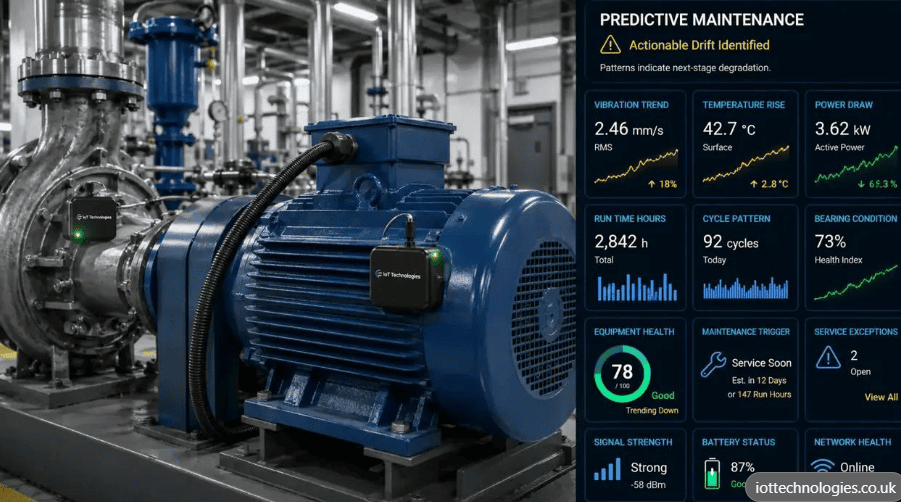
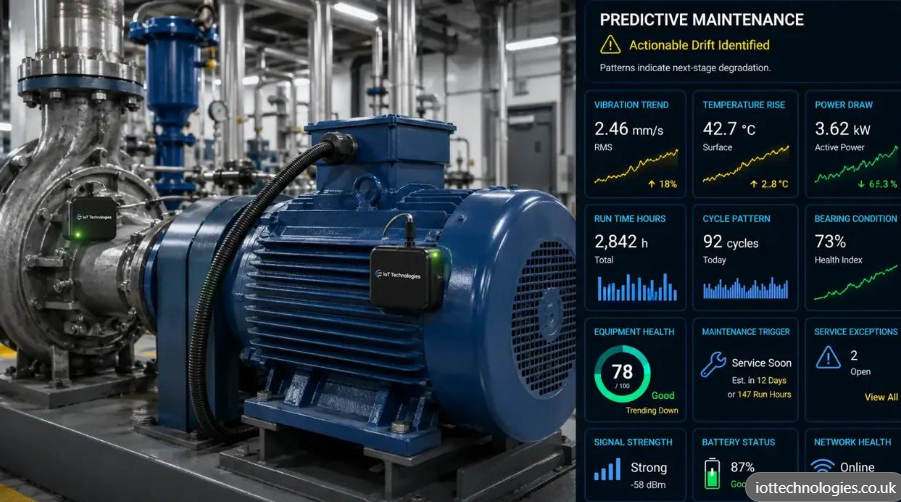

*Illustrative image only. It depicts a generic condition-monitoring dashboard and is not an output of this project. The dataset used here contains no vibration, bearing-health or time-series signals.*

## 1. Problem Definition

### The operational problem

When a machine fails unexpectedly, the cost is more than the repair: production stops, other components may be damaged, and corrective maintenance is usually more expensive than planned maintenance. If a model can rank machines by failure risk based on their current operating conditions, maintenance effort can be directed where it is most likely to matter.

### The learning task

Given five sensor-style measurements and the product quality variant of a machine, estimate

$$\hat{p}(\mathbf{x}) = P(\text{Machine failure} = 1 \mid \mathbf{x}),$$

and convert the estimated probability into an alert using a decision threshold $t$:

$$\hat{y} = \begin{cases} 1 & \text{if } \hat{p}(\mathbf{x}) \ge t \\ 0 & \text{otherwise.} \end{cases}$$

Two separate things are therefore being designed: a **scoring model** that produces $\hat{p}$, and a **decision rule** (the threshold) that turns the score into an action. Much of this notebook is about the second part, because with rare failures the default threshold of 0.5 is rarely appropriate.

| Input | Unit (per dataset documentation) |
|---|---|
| Type (quality variant L / M / H) | categorical |
| Air temperature | K |
| Process temperature | K |
| Rotational speed | rpm |
| Torque | N·m |
| Tool wear | min |

> **Methodological note — what this project is and is not.**
> The dataset has no continuous, timestamped sequences per machine. It therefore cannot support Remaining Useful Life (RUL) estimation or claims about predicting a failure minutes or hours in advance. The task is framed as **failure risk classification from concurrent operating conditions**.

### Tooling

* **Used in this notebook:** Python, pandas, NumPy, SciPy, scikit-learn, matplotlib, seaborn, joblib, ucimlrepo.
* **Planned for later engineering stages:** FastAPI, Pydantic, pytest, Docker, cloud deployment.

## 2. Dataset and Data Integrity

* **Dataset:** [AI4I 2020 Predictive Maintenance Dataset](http://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)
* **Source:** UCI Machine Learning Repository
* **Nature of the data:** 10,000 **synthetic** records
* **Original schema:** 14 columns, including the identifiers `UID` and `Product ID`
* **Schema retrieved in this notebook:** 12 columns. `UID` and `Product ID` are not present in the DataFrame returned by `ucimlrepo`, so they never need to be dropped here.

### Columns of the retrieved DataFrame

The column names in the retrieved DataFrame do not carry unit suffixes (for example `Air temperature`, not `Air temperature [K]`). Units below come from the dataset documentation.

| Column | Description | Role |
|---|---|---|
| `Type` | Product quality variant: L, M or H (about 60% / 30% / 10% of records; verified in Section 1.5) | Predictive feature |
| `Air temperature` | Ambient air temperature (K) | Predictive feature |
| `Process temperature` | Process temperature (K) | Predictive feature |
| `Rotational speed` | Shaft speed (rpm) | Predictive feature |
| `Torque` | Torque (N·m) | Predictive feature |
| `Tool wear` | Cumulative tool usage time (min) | Predictive feature |
| `Machine failure` | Binary label, 1 if the machine failed | **Target** |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | Indicators of the individual failure modes (tool wear, heat dissipation, power, overstrain, random) | Excluded (target leakage) |

### Why the failure-mode indicators are excluded

The five failure-mode flags are tied directly to how the overall `Machine failure` label is constructed. A model given these columns would be looking at a close restatement of the answer. Such a model would score impressively in evaluation and would be useless in practice, because the information in those flags is only known *after* a failure has happened, not at the moment a risk estimate is needed. They are therefore removed from the feature matrix when the data is split (Phase 2).

## 3. Target System Architecture

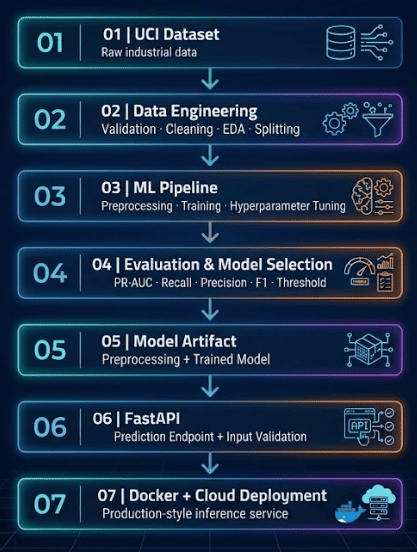

*The diagram shows the intended end-to-end system. Stages 01–05 (data, analysis, modelling, evaluation, model artifact) are carried out in this notebook. Stages 06 (FastAPI service) and 07 (Docker and cloud deployment) are planned and have not been implemented here.*
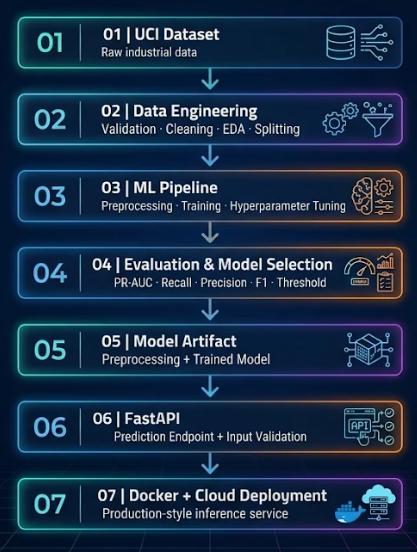

## 4. Project Roadmap

The work is organised in phases, each of which produces the decision that the next one depends on.

| Phase | Purpose | Status |
|---|---|---|
| 1. Data acquisition and exploration | Understand size, quality, class imbalance, distributions and outliers; test whether `Type` is associated with failure | Completed in this notebook |
| 2. Data preparation and feature engineering | Build candidate engineered features, define a leakage-free train / validation / test split, and design the preprocessing pipelines | Completed in this notebook |
| 3. Model development | Move from a trivial baseline to Logistic Regression, then to tree ensembles; study class weighting, thresholds and feature contribution; tune the strongest candidate | Completed in this notebook |
| 4. Final evaluation and persistence | Evaluate once on the untouched test set; save the model, threshold and metadata as one artifact; verify it reloads and predicts | Completed in this notebook |
| 5. API development and testing | FastAPI inference service, Pydantic input validation, pytest suite | Planned |
| 6. Packaging and deployment | Docker image, cloud deployment, documentation | Planned |

---

# Phase 1 — Data Acquisition and Exploratory Analysis

**Objective.** Learn what the data contains before choosing any modelling strategy.

**Why this comes first.** Almost every later decision depends on properties established here: whether data cleaning is needed, how severe the class imbalance is (which determines the evaluation metrics), whether any variable has an extreme distribution (which affects preprocessing), and whether the categorical `Type` variable carries a measurable signal.

**Method.** Retrieve the dataset, check its structure and integrity, inspect descriptive statistics and the target distribution, then investigate specific questions statistically: *is machine type associated with failure?*, *which features are skewed?*, *which observations are statistical outliers, and should they be removed?*

## 1.1 Data Acquisition

The next three cells install the `ucimlrepo` client, import the libraries used during exploration, and download the dataset with `fetch_ucirepo(id=601)`. The feature table and the target table are returned separately, so they are concatenated into a single DataFrame, `df`, to allow feature–target analysis.

In [3]:
!pip install -q ucimlrepo

In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

In [5]:
# Fetch dataset from UCI
dataset = fetch_ucirepo(id=601)

# Extract features and targets
X_raw = dataset.data.features
y_raw = dataset.data.targets

# Combine for initial inspection
df = pd.concat([X_raw, y_raw], axis=1)

The data is now in a single DataFrame. The next section checks its structure and integrity.

## 1.2 Structural and Integrity Checks

**Objective.** Confirm the size and schema of the data and determine whether cleaning is required.

**Rationale.** Missing values and duplicated records would require handling before modelling, and unexpected data types could indicate parsing problems.

**Method.** Inspect the shape and column list, the types and non-null counts (`df.info()`), the number of duplicated rows, and the descriptive statistics for all columns.

**Expected insight.** Whether the data can be used as-is, and what the scale and spread of each variable look like.

In [6]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nLast 5 records:")
display(df.tail(5))

Dataset shape: (10000, 12)

Columns:
['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Last 5 records:


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
9995,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [7]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type                 10000 non-null  object 
 1   Air temperature      10000 non-null  float64
 2   Process temperature  10000 non-null  float64
 3   Rotational speed     10000 non-null  int64  
 4   Torque               10000 non-null  float64
 5   Tool wear            10000 non-null  int64  
 6   Machine failure      10000 non-null  int64  
 7   TWF                  10000 non-null  int64  
 8   HDF                  10000 non-null  int64  
 9   PWF                  10000 non-null  int64  
 10  OSF                  10000 non-null  int64  
 11  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 937.6+ KB


In [8]:
print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
0


In [9]:
print("\nStatistical Summary:")
display(df.describe(include="all").T)


Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature,10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature,10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed,10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque,10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear,10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,NaN,NaN,NaN,0.0115,0.106625,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,NaN,NaN,NaN,0.0095,0.097009,0.0,0.0,0.0,0.0,1.0


## 1.3 Target Distribution and Class Imbalance

**Objective.** Measure how often failures occur.

**Rationale.** The proportion of the minority class determines which evaluation metrics are meaningful. If failures are rare, a model can look accurate while detecting none of them.

**Method.** Count the two classes, express them as percentages, and plot them.

In [10]:
target_distribution = df["Machine failure"].value_counts()

print("\nClass percentages:")
print(
    df["Machine failure"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


Class percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


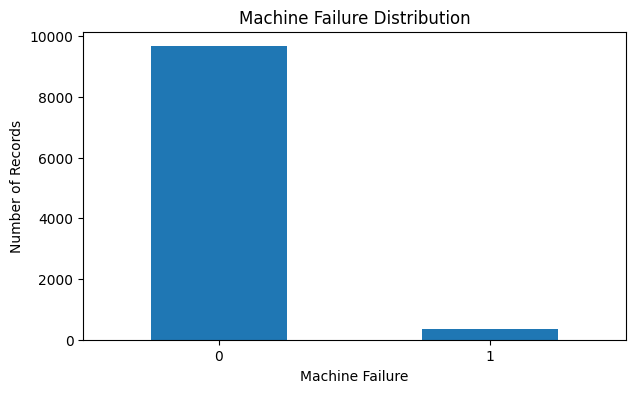

In [11]:
target_distribution.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.show()

## 1.4 What the Integrity Checks and Descriptive Statistics Tell Us

The preceding cells give the following picture. These are preliminary observations that guide the next steps; they are not modelling decisions yet.

### Completeness

The DataFrame has **10,000 rows and 12 columns**. All columns have 10,000 non-null values and there are **0 duplicated records**, so no imputation or de-duplication is needed. Completeness does not guarantee quality, which is why distributions and outliers are examined below.

### Categorical feature `Type`

`Type` has three categories (L, M, H). `L` is the most frequent (6,000 records, 60%), so the categories are far from evenly represented. Whether the category is related to failure is tested in Section 1.5.

### Temperature features

| Statistic | Air temperature (K) | Process temperature (K) |
|---|---:|---:|
| Mean | 300.00 | 310.01 |
| Median | 300.1 | 310.1 |
| Standard deviation | 2.00 | 1.48 |
| Minimum | 295.3 | 305.7 |
| Maximum | 304.5 | 313.8 |

Both means sit close to their medians. The two means differ by about 10 K:

$$310.01 - 300.00 \approx 10.00\ \text{K}.$$

An average gap says nothing about how the gap behaves from record to record or during failures, but it motivates examining the *difference* between the two temperatures as a candidate feature (Phase 2).

### Mechanical features

| Statistic | Rotational speed (rpm) | Torque (N·m) |
|---|---:|---:|
| Mean | 1538.78 | 39.99 |
| Median | 1503 | 40.1 |
| Standard deviation | 179.28 | 9.97 |
| 75th percentile | 1612 | 46.8 |
| Maximum | 2886 | 76.6 |

For rotational speed, the mean exceeds the median and the maximum (2886 rpm) lies far above the 75th percentile (1612 rpm), which suggests right skew. Torque's mean and median are nearly equal, but that alone does not prove symmetry; skewness is measured explicitly in Section 1.6.

### Tool wear

Mean 107.95 min, median 108 min, standard deviation 63.65 min, range 0–253 min. The wide range indicates considerable variation in accumulated wear.

### Target

The mean of the binary `Machine failure` column is the failure rate:

$$\bar{y} = 0.0339 \;\Rightarrow\; 3.39\%\ \text{of records are failures}.$$

In counts: **9,661 normal observations (96.61%)** and **339 failures (3.39%)**.

### Consequences for the rest of the project

1. No data cleaning is required.
2. Failures are rare, so **accuracy cannot be the primary metric**. A model that always predicts "no failure" would already be about 96.6% accurate. Metrics that focus on the minority class (precision, recall, F1, PR-AUC) are needed.
3. Splits must be **stratified** so that every subset contains enough failures to evaluate.
4. Rotational speed needs a closer look because of its apparent skew and extreme values.

## 1.5 Statistical Investigation: Is Machine Type Associated with Failure?

**Objective.** Test whether the failure rate differs between the L, M and H product variants.

**Rationale.** `Type` is the only categorical feature. Before deciding how much attention it deserves, it is worth checking whether its categories behave differently with respect to failure at all.

**Method.** Build the contingency table of `Type` against `Machine failure`, then apply a Pearson Chi-Square test of independence. The null hypothesis is that failure and type are independent. The test is complemented by the observed failure rate in each category.

**Expected insight.** A yes/no answer on statistical association, and, equally important, a sense of whether any detected association is large enough to matter.

In [12]:
from scipy.stats import chi2_contingency

# Contingency table
contingency_table = pd.crosstab(
    df["Type"],
    df["Machine failure"]
)

display(contingency_table)

Machine failure,0,1
Type,,
H,982,21
L,5765,235
M,2914,83


In [13]:
# Chi-Square test
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {p_value:.6f}")
print(f"Degrees of Freedom: {dof}")

if p_value < 0.05:
    print("Statistically significant association detected.")
else:
    print("No statistically significant association detected.")

Chi-Square Statistic: 13.7517
P-value: 0.001032
Degrees of Freedom: 2
Statistically significant association detected.


In [14]:
failure_by_type = (
    df.groupby("Type")["Machine failure"]
    .agg(["count", "sum", "mean"])
)

failure_by_type["failure_percentage"] = (
    failure_by_type["mean"] * 100
)

display(failure_by_type)

,count,sum,mean,failure_percentage
Type,,,,
H,1003,21,0.020937,2.093719
L,6000,235,0.039167,3.916667
M,2997,83,0.027694,2.769436


### Interpretation: Statistical Significance Versus Practical Effect Size

**Observed.** The contingency table and failure rates are:

| Type | Records | Share | No failure | Failure | Failure rate |
|---|---:|---:|---:|---:|---:|
| L | 6,000 | 60.00% | 5,765 | 235 | 3.9167% |
| M | 2,997 | 29.97% | 2,914 | 83 | 2.7694% |
| H | 1,003 | 10.03% | 982 | 21 | 2.0937% |

The Chi-Square test gives $\chi^2 = 13.7517$ with 2 degrees of freedom and $p = 0.001032$, so the null hypothesis of independence is rejected at the 5% level. The failure rate is highest for `L` and lowest for `H`.

**What this means.** There is statistical evidence that failure rates differ across types. The test uses a large sample, however, and with a large sample even small differences can produce small p-values. A p-value answers "is there any association?", not "how strong is it?". The latter requires an effect-size measure, such as Cramér's V:

$$V = \sqrt{\frac{\chi^2}{n\,(\min(r,c)-1)}}.$$

The notebook does not compute this quantity in code. Substituting the printed statistic ($\chi^2 = 13.7517$, $n = 10{,}000$, $\min(r,c)-1 = 1$) gives roughly $V \approx 0.037$ by hand, a very weak association by the usual conventions. The practical reading is simple: failure rates range only from about 2.1% to 3.9%, a narrow band around the overall rate of 3.39%, so knowing the type changes the estimated failure risk only slightly.

**Limitations.** The test says that the distribution of failures differs across types; it does not say which categories differ from which, and it does not show that type *causes* failure. All expected counts are comfortably above the usual minimum of 5 (the smallest is about 34, for failures in type H), so the Chi-Square approximation is reasonable.

**Decision.** `Type` is kept as a candidate feature and will be one-hot encoded, but it is not expected to be a dominant predictor. This expectation will be revisited when feature importance is measured.

**Next.** The numerical features are examined for skewness and extreme values.

## 1.6 Distribution Shape and Outlier Analysis

**Objective.** Quantify skewness and identify statistically extreme observations in each numerical feature.

**Rationale.** Strong skewness and heavy tails can influence scaling, linear models and the interpretation of summary statistics. The descriptive statistics already hinted at right skew in rotational speed.

**Method.** Compute the sample skewness of each numerical feature, then apply the Tukey IQR rule: an observation is flagged if it lies outside

$$[\,Q_1 - 1.5\,\mathrm{IQR},\; Q_3 + 1.5\,\mathrm{IQR}\,],\qquad \mathrm{IQR} = Q_3 - Q_1.$$

**Expected insight.** Which features are asymmetric, how many observations are flagged, and whether flagged observations look like data errors or like genuine operating states.

In [15]:
numerical_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

skewness = df[numerical_features].skew()

display(
    skewness.sort_values(
        ascending=False
    ).to_frame("Skewness")
)

,Skewness
Rotational speed,1.993171
Air temperature,0.114274
Tool wear,0.027292
Process temperature,0.015027
Torque,-0.009517


In [16]:
outlier_summary = []

for col in numerical_features:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_summary.append({
        "Feature": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": (
            len(outliers) / len(df) * 100
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df)

,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Air temperature,293.50,306.30,0,0.00
1,Process temperature,305.35,314.55,0,0.00
2,Rotational speed,1139.50,1895.50,418,4.18
3,Torque,12.80,67.20,69,0.69
4,Tool wear,-110.50,325.50,0,0.00


### Interpretation: Skewness and Outliers

| Feature | Skewness | IQR outliers | Share |
|---|---:|---:|---:|
| Rotational speed | 1.9932 | 418 | 4.18% |
| Air temperature | 0.1143 | 0 | 0% |
| Tool wear | 0.0273 | 0 | 0% |
| Process temperature | 0.0150 | 0 | 0% |
| Torque | -0.0095 | 69 | 0.69% |

**Observed.** Rotational speed is strongly right-skewed (skewness about 2.0); the other four features are close to symmetric (absolute skewness below 0.12). Only rotational speed (418 flagged, bounds 1139.5–1895.5 rpm) and torque (69 flagged, bounds 12.8–67.2 N·m) contain IQR outliers. Because the minimum speed in the data (1168 rpm) is above the lower bound, all 418 flagged speed values are on the high side.

**What this means.** An IQR outlier is a statistical observation, not an automatically erroneous measurement. The IQR rule assumes a roughly symmetric distribution; applied to a right-skewed variable it will flag a long upper tail even if every value is physically plausible. A machine running faster or under unusually low or high torque is a legitimate operating state.

**Decision: the flagged observations are not removed.** Deleting them would discard real operating conditions, which are the kind of unusual conditions in which failures may be concentrated. It would also alter the class balance and reduce the number of already scarce failure examples, with no evidence that these records are measurement errors. Their influence on the models is addressed through model choice and preprocessing rather than deletion.

**Next.** Box plots compare each feature across the normal and failure classes, including how the flagged observations are distributed between them.

### Box plots by failure status

**Objective.** See how each feature's distribution differs between normal and failure observations.

**Method.** One box plot per numerical feature, split by `Machine failure`.

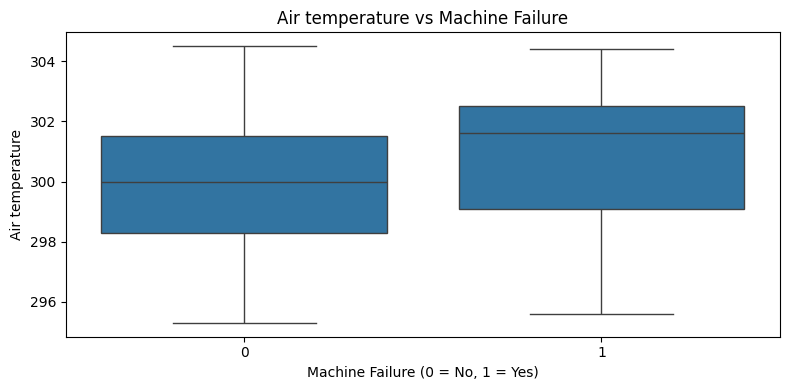

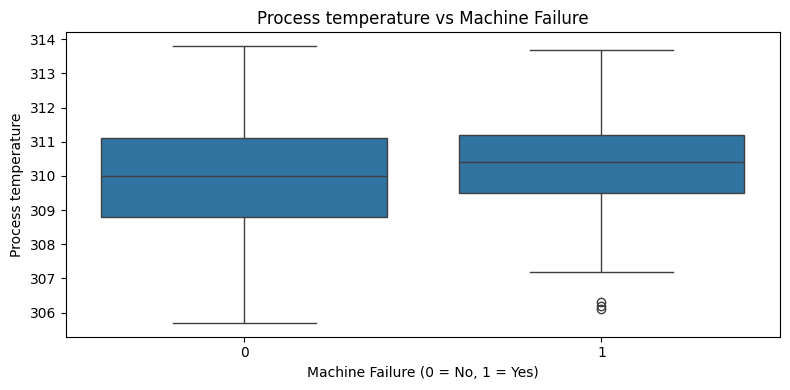

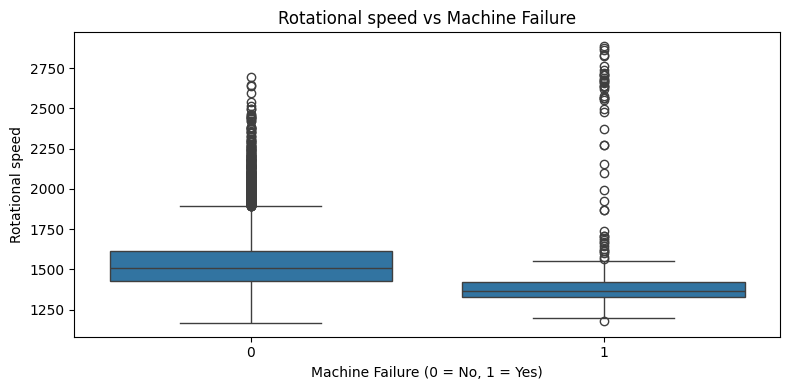

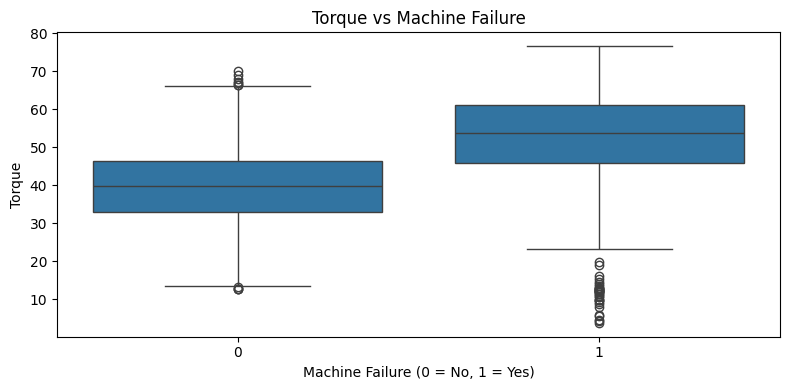

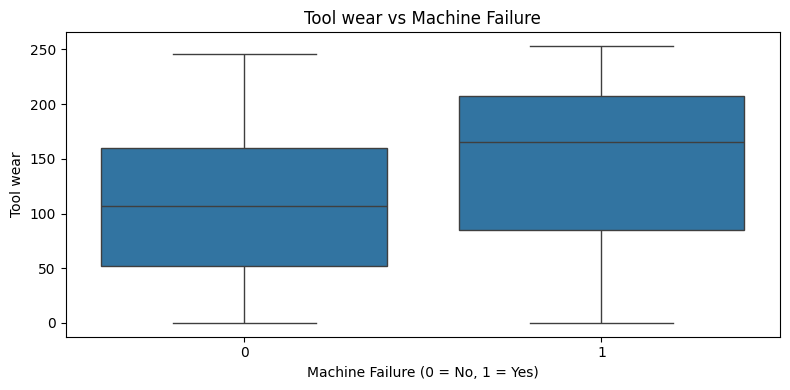

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in numerical_features:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="Machine failure",
        y=col
    )

    plt.title(f"{col} vs Machine Failure")
    plt.xlabel("Machine Failure (0 = No, 1 = Yes)")

    plt.tight_layout()
    plt.show()

### 1.7 Interpretation: Feature Behaviour by Failure Status

**Observed.** The box plots show overlapping distributions for every feature, with some systematic shifts for failures:

* **Rotational speed:** the median is lower in the failure group, and the largest speed values (up to about 2,900 rpm) occur in the failure group.
* **Torque:** the median is higher in the failure group, and the lowest torque values (down to a few N·m) also occur in the failure group.
* **Tool wear:** the median and upper quartile are higher for failures.
* **Air and process temperature:** failures show slightly higher medians, with heavy overlap.

**What this means.** No single feature separates the two classes cleanly, and the largest shifts occur for speed, torque and tool wear. Some of the outliers flagged in Section 1.6 are concentrated in the failure group, which reinforces the decision not to delete them.

**Limitations.** Box plots show one variable at a time. They cannot reveal interactions, and the failure group contains only 339 records, so the visual impressions are descriptive rather than conclusive.

**Next.** Torque and rotational speed shift in *opposite* directions for failures, which suggests that their combination, rather than either alone, may be informative. That idea, together with the temperature observation from Section 1.4, leads to feature engineering.

# Phase 2 — Data Preparation and Feature Engineering

**Objective.** Convert the exploratory findings into a modelling-ready setup: candidate engineered features, a leakage-free data split, and preprocessing pipelines.

**Rationale.** Phase 1 showed that no cleaning is needed, that failures are rare, and that some features interact physically. The decisions made here (which columns enter the model, how the data is divided, how features are transformed) determine whether later evaluation numbers can be trusted.

**Method.** Create two physically motivated features, split the data with stratification into training, validation and test sets, and define preprocessing inside scikit-learn `Pipeline` objects.

## 2.1 Candidate Engineered Features

Two features are investigated. They are candidates: neither is assumed to be useful until it has been tested (Section 3.4).

### Temperature difference

$$\text{Temp\_Diff} = T_{\text{process}} - T_{\text{air}}$$

*Intuition.* A given process temperature means something different depending on the ambient temperature. The gap between the two is a simple proxy for how much heat the process holds relative to its surroundings, and so potentially for how effectively heat is being dissipated. This is a hypothesis motivated by the temperature observations in Section 1.4; the notebook does not claim a physical mechanism.

### Mechanical power

$$P = \tau \cdot \omega, \qquad \omega = n_{\text{rpm}} \cdot \frac{2\pi}{60} \quad\Rightarrow\quad P = \tau \cdot n_{\text{rpm}} \cdot \frac{2\pi}{60}$$

* $\tau$ is torque in N·m.
* $n_{\text{rpm}}$ is rotational speed in revolutions per minute; multiplying by $2\pi/60$ converts it to angular velocity $\omega$ in radians per second.
* $P$ is then mechanical power in watts, assuming the dataset units are as documented.

*Intuition.* Torque and speed each describe part of the mechanical load. Their product describes the rate at which work is done. Section 1.7 showed that failures shift toward higher torque and lower speed, so the combination is a natural quantity to examine. A linear model cannot form a product of two inputs by itself, so providing power explicitly gives it an interaction term it could not otherwise represent.

The cell below adds both features to a copy of the DataFrame (`df_engineered`) and summarises them. The original `df` is untouched. Both features are computed row by row from that row's own values, with no statistics learned from the data, so computing them before splitting does not leak information between sets.

In [18]:
import numpy as np

df_engineered = df.copy()

# Temperature difference
df_engineered["Temp_Diff"] = (
    df_engineered["Process temperature"]
    - df_engineered["Air temperature"]
)

# Mechanical power in Watts
df_engineered["Power"] = (
    df_engineered["Torque"]
    * df_engineered["Rotational speed"]
    * (2 * np.pi / 60)
)

df_engineered[
    [
        "Air temperature",
        "Process temperature",
        "Temp_Diff",
        "Rotational speed",
        "Torque",
        "Power"
    ]
].describe()

,Air temperature,Process temperature,Temp_Diff,Rotational speed,Torque,Power
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,300.004930,310.005560,10.000630,1538.776100,39.986910,6279.744953
std,2.000259,1.483734,1.001094,179.284096,9.968934,1067.418295
min,295.300000,305.700000,7.600000,1168.000000,3.800000,1148.440610
25%,298.300000,308.800000,9.300000,1423.000000,33.200000,5561.184484
50%,300.100000,310.100000,9.800000,1503.000000,40.100000,6271.027344
75%,301.500000,311.100000,11.000000,1612.000000,46.800000,7003.002724
max,304.500000,313.800000,12.100000,2886.000000,76.600000,10469.923005


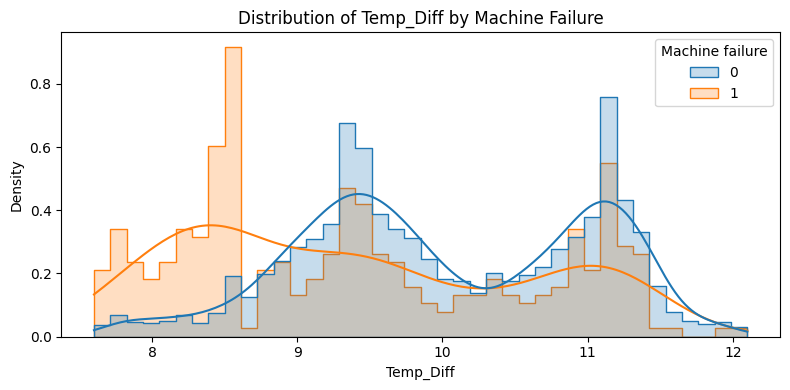

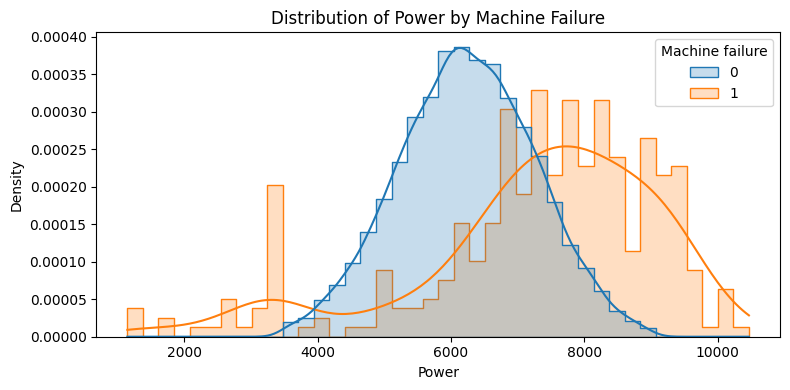

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

new_features = ["Temp_Diff", "Power"]

for col in new_features:
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df_engineered,
        x=col,
        hue="Machine failure",
        bins=40,
        kde=True,
        element="step",
        stat="density",
        common_norm=False
    )

    plt.title(f"Distribution of {col} by Machine Failure")
    plt.tight_layout()
    plt.show()

### Interpretation: Engineered Feature Distributions

**Observed.** `Temp_Diff` has mean 10.00 K, standard deviation 1.00 K and range 7.6–12.1 K. `Power` has mean of about 6,280 W, standard deviation about 1,067 W and range about 1,148–10,470 W. In the density plots, normal observations of `Power` form a single bell-shaped peak near 6,000 W, while failures are shifted toward higher values with a broad spread and a small secondary cluster at low power. `Temp_Diff` for normal observations shows two peaks (near 9.4 K and 11.1 K), while failures concentrate more strongly at lower values around 8–8.6 K.

**What this means.** Both features show visible differences between the classes, so both justify a controlled test.

**Limitations.** Visual separation in a density plot does not establish predictive value. The failure histograms are based on 339 records and are noisy, and the plots are marginal views that ignore other features.

**Decision.** Keep both candidates for now. They will be tested in a feature ablation experiment (Section 3.4) before either is committed to the final model.

## 2.2 Train / Validation / Test Strategy

**Objective.** Divide the data so that each model decision is made on data that did not influence the model it evaluates.

**Rationale.** Evaluating a model on the data it was trained on measures memorisation. Reusing the same evaluation data for every decision gradually tailors the model to it. Three separate subsets keep these roles apart.

| Subset | Role |
|---|---|
| **Training** | Fitting model parameters and preprocessing statistics; cross-validation during hyperparameter search |
| **Validation** | Comparing models, comparing feature sets, selecting the decision threshold, choosing the final model |
| **Test** | One final, unbiased evaluation, after all decisions are complete |

**Method.** Two stratified `train_test_split` calls with `random_state=42`: first 70% training versus 30% held out, then the held-out portion is divided evenly into validation and test (15% each). Stratification preserves the roughly 3.4% failure rate in every subset. The columns `Machine failure`, `TWF`, `HDF`, `PWF`, `OSF` and `RNF` are removed from the feature matrix at this point, so failure-mode flags cannot reach the model.

In [20]:
from sklearn.model_selection import train_test_split

target = "Machine failure"

excluded_columns = [
    "Machine failure",
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

X = df_engineered.drop(columns=excluded_columns)
y = df_engineered[target]

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training:", X_train.shape, y_train.value_counts().to_dict())
print("Validation:", X_val.shape, y_val.value_counts().to_dict())
print("Test:", X_test.shape, y_test.value_counts().to_dict())

Training: (7000, 8) {0: 6763, 1: 237}
Validation: (1500, 8) {0: 1449, 1: 51}
Test: (1500, 8) {0: 1449, 1: 51}


### Interpretation: Split Sizes and Class Balance

| Split | Records | Share | Normal | Failure | Failure rate |
|---|---:|---:|---:|---:|---:|
| Training | 7,000 | 70% | 6,763 | 237 | 3.39% |
| Validation | 1,500 | 15% | 1,449 | 51 | 3.40% |
| Test | 1,500 | 15% | 1,449 | 51 | 3.40% |

Each feature matrix has 8 columns: `Type`, the five original numerical features, and the two engineered features. Stratification kept the class ratio essentially constant across subsets.

**Limitation.** Validation and test each contain only **51 failures**. Metrics that depend on the minority class, such as recall and precision, will be noisy: one failure more or fewer shifts recall by about $1/51 \approx 2$ percentage points. This will matter repeatedly when interpreting small differences between models.

**Discipline going forward.** The test set is not used for model selection, feature selection or threshold tuning. It is touched once, in Phase 4.

## 2.3 Preprocessing Architecture

**Objective.** Define how raw columns are transformed into model inputs.

**Rationale.** Different model families have different requirements. Logistic Regression is sensitive to feature scale. Tree-based models are not, because they split on thresholds and a monotonic rescaling of a feature does not change which splits are possible.

**Method.** Use `ColumnTransformer` inside a `Pipeline`:

* **For Logistic Regression:** `StandardScaler` on numerical features, $z = (x - \mu)/\sigma$ with $\mu$ and $\sigma$ learned from the training data, and `OneHotEncoder` on `Type`.
* **For tree-based models (defined later in Section 3.5):** `OneHotEncoder` on `Type`, with numerical features passed through unscaled.

Without scaling, Logistic Regression would treat a feature measured in thousands (rotational speed, in rpm) very differently from one measured in tens (torque, in N·m): optimisation would converge more slowly and its default L2 regularisation would penalise coefficients unevenly. One-hot encoding is used for `Type` because it is nominal; it avoids imposing an artificial numeric order on L, M and H.

**Why the preprocessing lives inside the pipeline.** The transformers are fitted only on training data and then applied unchanged to validation data, test data and, later, new inputs at inference time. This prevents information from validation or test sets leaking into the scaling statistics, and it guarantees the same transformation is used in training and in production, because the saved model carries its own preprocessing.

The first cell below defines the Logistic Regression preprocessor. At this stage, `numerical_features` includes both engineered features; whether they deserve to stay is decided in Section 3.4.

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

categorical_features = ["Type"]

numerical_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear",
    "Temp_Diff",
    "Power"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

### Preprocessing diagnostic

The next cell fits the preprocessor on the training data and applies it to the validation data. It is a **diagnostic check** of the transformed matrix dimensions and is not a separate final model pipeline. The pipelines used for actual modelling fit their own preprocessing inside each model.

In [22]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)

Training shape: (7000, 10)
Validation shape: (1500, 10)


**Observed.** The transformed training matrix has shape (7000, 10) and the validation matrix (1500, 10).

**What this means.** The 10 columns are 7 standardised numerical features (five original, plus `Temp_Diff` and `Power`) and 3 one-hot columns for `Type`. Row counts match the split sizes, and the validation matrix has the same number of columns as the training matrix, so the preprocessor behaves as intended.

**Next.** Phase 3 begins model development, starting from the simplest possible reference point.

# Phase 3 — Model Development

**Objective.** Identify a model family, feature set and decision rule that detect failures effectively, using the validation set for every comparison.

**Approach.** The models are developed as a chain of experiments, each answering a question raised by the previous one:

1. **Dummy baseline:** what does a model with no knowledge achieve? (This will show why accuracy is misleading.)
2. **Logistic Regression, standard and class-weighted:** how much can a linear model detect, and what does class weighting change?
3. **Threshold analysis:** how much of the apparent performance is determined by the 0.5 cut-off rather than by the model?
4. **Feature ablation:** do the engineered features add information?
5. **Tree-based models:** does a non-linear ensemble perform better?
6. **Threshold analysis for tree models:** which operating points are available?
7. **Hyperparameter optimisation, tuned model evaluation and threshold selection:** can the best candidate be improved, and which operating point should the system use?
8. **Permutation importance:** which features does the final model rely on?

All comparisons in this phase use the validation set.

## 3.1 Baseline: A Model That Always Predicts "No Failure"

**Objective.** Establish the performance of a classifier that uses no information from the features.

**Rationale.** A result is only meaningful relative to a reference. With 3.4% failures, a model that learns nothing can still look good on some metrics.

**Method.** `DummyClassifier(strategy="most_frequent")` inside the standard pipeline, evaluated on the validation set with accuracy, precision, recall, F1, PR-AUC, ROC-AUC, the confusion matrix and a classification report.

For reference, the metrics used throughout this notebook are defined from the confusion matrix entries, where TP, FP, FN and TN denote true positives, false positives, false negatives and true negatives. In `scikit-learn`, the confusion matrix is laid out as `[[TN, FP], [FN, TP]]`.

$$\text{Precision} = \frac{TP}{TP + FP}, \qquad \text{Recall} = \frac{TP}{TP + FN}, \qquad F_1 = \frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}}$$

In this project, **precision** answers "of the machines flagged as at-risk, how many really failed?", and **recall** answers "of the machines that really failed, how many were flagged?". **PR-AUC** (average precision) summarises the precision–recall trade-off across all thresholds; a model with no skill has a PR-AUC equal to the failure prevalence. **ROC-AUC** measures how well the model ranks failures above normal records across all thresholds.

In [23]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline

baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]
)

baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

y_val_pred = baseline_model.predict(X_val)
y_val_proba = baseline_model.predict_proba(X_val)[:, 1]

print("Baseline Model Evaluation")
print("-" * 40)

print(f"Accuracy:  {accuracy_score(y_val, y_val_pred):.4f}")
print(f"Precision: {precision_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_val, y_val_pred, zero_division=0):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, y_val_proba):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, y_val_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred, zero_division=0))

Baseline Model Evaluation
----------------------------------------
Accuracy:  0.9660
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
PR-AUC:    0.0340
ROC-AUC:   0.5000

Confusion Matrix:
[[1449    0]
 [  51    0]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1449
           1       0.00      0.00      0.00        51

    accuracy                           0.97      1500
   macro avg       0.48      0.50      0.49      1500
weighted avg       0.93      0.97      0.95      1500



### Interpretation: Why a Useless Model Scores 96.6% Accuracy

**Observed.**

| Metric | Value |
|---|---:|
| Accuracy | 0.9660 |
| Precision | 0 |
| Recall | 0 |
| F1 | 0 |
| PR-AUC | 0.0340 |
| ROC-AUC | 0.5000 |

Confusion matrix: `[[1449, 0], [51, 0]]`.

**What this means.** The baseline never predicts a failure, so it detects none of the 51 failures, yet it achieves 0.9660 accuracy simply because 1,449 of the 1,500 validation records are normal. Its PR-AUC (0.0340) equals the validation failure prevalence ($51/1500$), and its ROC-AUC of 0.5 is that of a model with no ranking ability.

**Decision.** Accuracy is not used to select models. Selection relies on **PR-AUC** (threshold-independent, focused on the rare class) together with precision, recall and F1 at specific thresholds. The baseline PR-AUC of 0.0340 is the floor that any useful model must clearly exceed.

## 3.2 Logistic Regression: Standard Versus Class-Weighted

**Objective.** Measure what a linear, interpretable model can achieve, and test the effect of class weighting.

**Rationale.** Logistic Regression is a natural first model: it is fast, well understood and gives a reference point for more complex models. With imbalanced data, the training loss is dominated by the majority class, so the model has little incentive to focus on failures. One common countermeasure is `class_weight="balanced"`, which weights each class inversely to its frequency:

$$w_c = \frac{n}{K\,n_c}.$$

With $n = 7000$, $K = 2$ classes and $n_1 = 237$ failures in the training set, a failure record receives a weight of roughly 14.8 and a normal record roughly 0.52 (arithmetic from the formula, not a notebook output).

**Method.** Train two pipelines on the same preprocessing: **Experiment A**, standard Logistic Regression, and **Experiment B**, the class-weighted variant. Both are evaluated on the validation set at the default threshold of 0.5.

**Expected insight.** Whether class weighting improves the model's ability to *rank* failures (PR-AUC, ROC-AUC) or mostly changes where its decisions fall (precision and recall).

At this stage both models use the full preprocessor from Section 2.3, which includes `Temp_Diff` and `Power`. The second cell defines a reusable evaluation function (it produces no output of its own).

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Experiment A: Standard Logistic Regression
log_reg = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]
)

# Experiment B: Balanced Logistic Regression
log_reg_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]
)

# Train both models
log_reg.fit(X_train, y_train)
log_reg_balanced.fit(X_train, y_train)

print("Both Logistic Regression models trained successfully.")

Both Logistic Regression models trained successfully.


In [26]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

def evaluate_model(model, X_val, y_val, model_name):
    y_pred = model.predict(X_val)
    y_proba = model.predict_proba(X_val)[:, 1]

    results = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(y_val, y_proba),
        "ROC-AUC": roc_auc_score(y_val, y_proba)
    }

    print(f"\n{model_name}")
    print("-" * 45)

    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_val, y_pred))

    return results

In [27]:
results = []

results.append(
    evaluate_model(
        log_reg,
        X_val,
        y_val,
        "Logistic Regression"
    )
)

results.append(
    evaluate_model(
        log_reg_balanced,
        X_val,
        y_val,
        "Logistic Regression (Balanced)"
    )
)

results_df = pd.DataFrame(results)

display(
    results_df
    .set_index("Model")
    .round(4)
)


Logistic Regression
---------------------------------------------
Accuracy: 0.9673
Precision: 0.5500
Recall: 0.2157
F1-score: 0.3099
PR-AUC: 0.3902
ROC-AUC: 0.9001

Confusion Matrix:
[[1440    9]
 [  40   11]]

Logistic Regression (Balanced)
---------------------------------------------
Accuracy: 0.8707
Precision: 0.1765
Recall: 0.7647
F1-score: 0.2868
PR-AUC: 0.3874
ROC-AUC: 0.9072

Confusion Matrix:
[[1267  182]
 [  12   39]]


,Accuracy,Precision,Recall,F1-score,PR-AUC,ROC-AUC
Model,,,,,,
Logistic Regression,0.9673,0.5500,0.2157,0.3099,0.3902,0.9001
Logistic Regression (Balanced),0.8707,0.1765,0.7647,0.2868,0.3874,0.9072


### Interpretation: What Class Weighting Changes

**Observed.** Validation results at threshold 0.5:

| Metric | Standard | Balanced |
|---|---:|---:|
| Accuracy | 0.9673 | 0.8707 |
| Precision | 0.5500 | 0.1765 |
| Recall | 0.2157 | 0.7647 |
| F1 | 0.3099 | 0.2868 |
| PR-AUC | 0.3902 | 0.3874 |
| ROC-AUC | 0.9001 | 0.9072 |

Confusion matrices: standard `[[1440, 9], [40, 11]]`; balanced `[[1267, 182], [12, 39]]`.

**What this means.** Class weighting traded precision for recall. The balanced model finds 39 of 51 failures instead of 11, but raises 182 false alarms instead of 9, which is why its accuracy falls to 0.8707 and its precision to 0.1765. Its F1 (0.2868) is slightly below the standard model's (0.3099). Notably, the threshold-independent metrics are almost the same (PR-AUC 0.3902 versus 0.3874, ROC-AUC 0.9001 versus 0.9072). Weighting therefore appears to have mostly shifted the model's operating point and not its ability to rank failures above normal records.

Two further points are visible in the numbers. First, ROC-AUC is about 0.90 for both models while PR-AUC is only about 0.39; with this much imbalance, ROC-AUC can look reassuring while precision remains poor. Second, class weighting is not universally beneficial: its effect depends on the data, the model and what the application needs. Whether 39 detections at the cost of 182 false alarms is better than 11 detections with 9 false alarms depends on operational costs, which are not defined in this project.

**Limitations.** The comparison uses a single threshold (0.5) and 51 validation failures.

**Next.** If weighting mainly moves the operating point, then simply moving the decision threshold on the standard model might give a similar trade-off. This is tested in Section 3.3.

## 3.3 Decision Threshold Analysis for Logistic Regression

**Objective.** Separate the effect of the *decision threshold* from the effect of *model training*.

**Rationale.** The threshold of 0.5 is a software default, not a property of the problem. A model outputs a score $\hat{p}$; where to cut that score is a separate design decision.

**Method.** For each model, evaluate thresholds from 0.05 to 0.95 in steps of 0.05, recording precision, recall, F1 and the confusion matrix entries (TP, FP, FN, TN). The first cell defines the evaluation function, the second applies it to both models, and the third plots precision and recall against the threshold.

**Expected insight.** The precision–recall trade-off available from each model and whether weighting and thresholding produce comparable operating points.

In [28]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import pandas as pd
import numpy as np

def evaluate_thresholds(model, X_val, y_val, model_name):

    probabilities = model.predict_proba(X_val)[:, 1]

    thresholds = np.arange(0.05, 0.96, 0.05)

    results = []

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn
        })

    return pd.DataFrame(results)

In [29]:
threshold_results = pd.concat(
    [
        evaluate_thresholds(
            log_reg,
            X_val,
            y_val,
            "Standard LR"
        ),
        evaluate_thresholds(
            log_reg_balanced,
            X_val,
            y_val,
            "Balanced LR"
        )
    ],
    ignore_index=True
)

display(
    threshold_results.round(4)
)

,Model,Threshold,Precision,Recall,F1-score,TP,FP,FN,TN
0,Standard LR,0.05,0.1919,0.6471,0.2960,33,139,18,1310
1,Standard LR,0.10,0.2632,0.4902,0.3425,25,70,26,1379
2,Standard LR,0.15,0.3478,0.4706,0.4000,24,45,27,1404
3,Standard LR,0.20,0.4364,0.4706,0.4528,24,31,27,1418
4,Standard LR,0.25,0.4286,0.4118,0.4200,21,28,30,1421
5,Standard LR,0.30,0.4634,0.3725,0.4130,19,22,32,1427
6,Standard LR,0.35,0.4848,0.3137,0.3810,16,17,35,1432
7,Standard LR,0.40,0.5417,0.2549,0.3467,13,11,38,1438
8,Standard LR,0.45,0.5238,0.2157,0.3056,11,10,40,1439
9,Standard LR,0.50,0.5500,0.2157,0.3099,11,9,40,1440


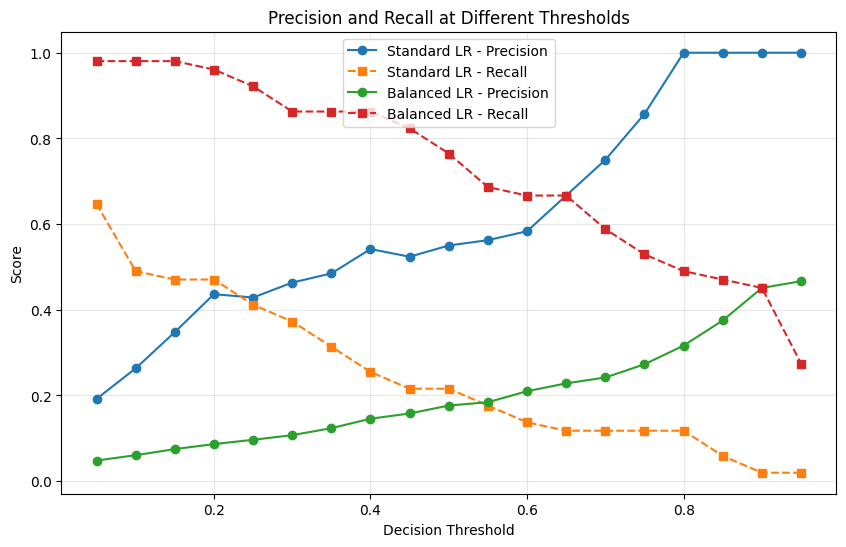

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for model_name in threshold_results["Model"].unique():

    subset = threshold_results[
        threshold_results["Model"] == model_name
    ]

    plt.plot(
        subset["Threshold"],
        subset["Precision"],
        marker="o",
        label=f"{model_name} - Precision"
    )

    plt.plot(
        subset["Threshold"],
        subset["Recall"],
        marker="s",
        linestyle="--",
        label=f"{model_name} - Recall"
    )

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision and Recall at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Interpretation: Threshold Analysis and the Precision–Recall Trade-off

**Observed.**

* **Lowering the threshold** raises recall, because more records are classified as potential failures, but increases false positives. For standard Logistic Regression at 0.05, recall is 0.6471 with 139 false positives (precision 0.1919). For balanced Logistic Regression at 0.05, recall reaches 0.9804 with 991 false positives (precision 0.0480).
* **Raising the threshold** improves precision but misses more failures. Standard Logistic Regression reaches precision 1.0 at thresholds of 0.80 and above, but recall is then only 0.1176 or lower.
* The two models can produce comparable operating points at different thresholds. Standard Logistic Regression at 0.20 (precision 0.4364, recall 0.4706, F1 0.4528) and balanced Logistic Regression at 0.90 (precision 0.4510, recall 0.4510, F1 0.4510) are almost the same.
* Across the whole scan, neither model exceeds an F1 of about 0.45.

**What this means.** Moving the threshold and applying class weights are different interventions. Threshold adjustment changes the decision rule *after* the model has been trained, leaving the scores unchanged. `class_weight="balanced"` changes the training loss and therefore the fitted model. In this experiment they largely move along the same precision–recall trade-off, which is consistent with the near-identical PR-AUC values seen in Section 3.2. The best F1 of about 0.45 is also a signal about the model family: a linear classifier on these features seems unable to achieve both good precision and good recall at once. This is consistent with failures depending on non-linear interactions among the features, a possibility that tree-based models are better suited to explore; this notebook does not test that explanation directly.

**Limitations.** The threshold grid has a resolution of 0.05, and each point rests on 51 failures.

**Decision.** No final threshold is chosen at this stage. The right operating point depends on the relative cost of missing a failure (a false negative) versus raising an unnecessary maintenance alert (a false positive). No cost function has been defined for this project, and none is assumed. Models continue to be compared mainly by validation PR-AUC, with precision–recall trade-offs examined afterwards. The test set remains untouched.

**Next.** Before comparing model families, the engineered features need to be tested in a controlled way, because the Logistic Regression models above included both of them without evidence that they help.

## 3.4 Feature Ablation Study

**Objective.** Determine whether `Temp_Diff` and `Power` contribute predictive information beyond the original features.

**Rationale.** Engineered features are hypotheses. Adding them without testing risks unnecessary complexity and makes it impossible to know which ones matter.

**Method.** A controlled experiment in which only the feature set changes. Four configurations are each trained with standard and class-weighted Logistic Regression, using identical hyperparameters, preprocessing logic, split and `random_state`, and evaluated at threshold 0.5 on the validation set:

| Set | Features |
|---|---|
| A | Original features only |
| B | Original + `Temp_Diff` |
| C | Original + `Power` |
| D | Original + both |

Because everything except the feature set is held constant, differences in the metrics can be attributed to the features. The first cell defines the four feature sets, the second trains and evaluates the eight models, and the third plots the PR-AUC comparison.

In [31]:
import pandas as pd
import numpy as np

base_numerical_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

feature_sets = {
    "A - Original Features": base_numerical_features,

    "B - Original + Temp_Diff": (
        base_numerical_features + ["Temp_Diff"]
    ),

    "C - Original + Power": (
        base_numerical_features + ["Power"]
    ),

    "D - Original + Both": (
        base_numerical_features + ["Temp_Diff", "Power"]
    )
}

categorical_features = ["Type"]

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

for feature_set_name, numerical_features in feature_sets.items():

    X_train_exp = X_train[numerical_features + categorical_features]
    X_val_exp = X_val[numerical_features + categorical_features]

    for model_type in ["Standard", "Balanced"]:

        preprocessor_exp = ColumnTransformer(
            transformers=[
                ("num", StandardScaler(), numerical_features),
                ("cat", OneHotEncoder(handle_unknown="ignore"),
                 categorical_features)
            ]
        )

        if model_type == "Standard":
            classifier = LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        else:
            classifier = LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )

        model = Pipeline([
            ("preprocessor", preprocessor_exp),
            ("classifier", classifier)
        ])

        model.fit(X_train_exp, y_train)

        probabilities = model.predict_proba(X_val_exp)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        results.append({
            "Feature Set": feature_set_name,
            "Model": model_type,
            "PR-AUC": average_precision_score(y_val, probabilities),
            "ROC-AUC": roc_auc_score(y_val, probabilities),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            )
        })

ablation_results = pd.DataFrame(results)

display(
    ablation_results.sort_values(
        by=["Model", "PR-AUC"],
        ascending=[True, False]
    ).round(4)
)

,Feature Set,Model,PR-AUC,ROC-AUC,Precision,Recall,F1-score
7,D - Original + Both,Balanced,0.3874,0.9072,0.1765,0.7647,0.2868
5,C - Original + Power,Balanced,0.3873,0.9071,0.1757,0.7647,0.2857
1,A - Original Features,Balanced,0.3829,0.8750,0.1365,0.7255,0.2298
3,B - Original + Temp_Diff,Balanced,0.3828,0.8751,0.1365,0.7255,0.2298
4,C - Original + Power,Standard,0.3908,0.9002,0.5500,0.2157,0.3099
6,D - Original + Both,Standard,0.3902,0.9001,0.5500,0.2157,0.3099
2,B - Original + Temp_Diff,Standard,0.3870,0.8639,0.6364,0.1373,0.2258
0,A - Original Features,Standard,0.3844,0.8622,0.6364,0.1373,0.2258


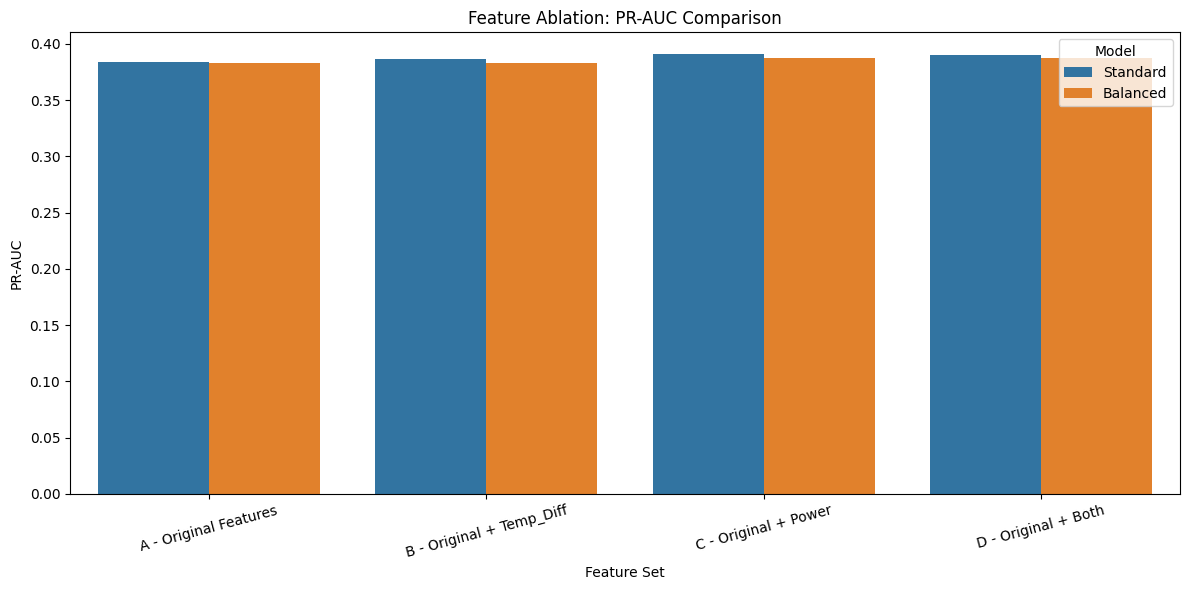

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=ablation_results,
    x="Feature Set",
    y="PR-AUC",
    hue="Model"
)

plt.title("Feature Ablation: PR-AUC Comparison")
plt.xlabel("Feature Set")
plt.ylabel("PR-AUC")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Interpretation: Which Engineered Features Help?

**Observed.** Validation results at threshold 0.5:

| Feature set | PR-AUC (Standard) | ROC-AUC (Standard) | PR-AUC (Balanced) | ROC-AUC (Balanced) |
|---|---:|---:|---:|---:|
| A — Original | 0.3844 | 0.8622 | 0.3829 | 0.8750 |
| B — Original + `Temp_Diff` | 0.3870 | 0.8639 | 0.3828 | 0.8751 |
| C — Original + `Power` | **0.3908** | 0.9002 | 0.3873 | 0.9071 |
| D — Original + both | 0.3902 | 0.9001 | 0.3874 | 0.9072 |

* Adding `Power` produced the highest standard-model PR-AUC (0.3908, against 0.3844 for original features only) and a clear rise in ROC-AUC (0.8622 to 0.9002 for the standard model; 0.8750 to 0.9071 for the balanced model).
* Adding `Temp_Diff` alone made no meaningful difference to either model (PR-AUC 0.3870 versus 0.3844 for the standard model; 0.3828 versus 0.3829 for the balanced one).
* Combining both features did not improve on `Power` alone in the standard model (0.3902 versus 0.3908); in the balanced model the two are essentially identical (0.3874 versus 0.3873).

**What this means.** `Power` was the more consistently useful feature. The PR-AUC differences are small in absolute terms (under 0.007) and come from a single validation split with 51 failures, so they should not be over-interpreted individually; the ROC-AUC gain is larger and appears in both model types. The lack of benefit from `Temp_Diff` has a straightforward explanation for a linear model. `Temp_Diff` is an exact linear combination of two features already present, so Logistic Regression with both temperatures could already represent anything `Temp_Diff` offers. `Power` is a product of two features, an interaction that a linear model cannot form on its own, so it can add genuinely new information.

**Limitations.** The ablation was run on Logistic Regression only. That is a reason to be modest about the conclusion for `Temp_Diff`: a non-linear model might use it differently, and this experiment cannot say. These results also do not show that `Power` is universally useful, or that it is causally related to failure; it is a feature that helped a particular model on a particular synthetic dataset.

**Decision.** Subsequent models use the **five original numerical features plus `Power`**, together with `Type`. `Temp_Diff` is excluded because it showed no meaningful improvement, and simpler feature sets are preferable when they perform comparably. This decision is carried into all tree-based models and the final model.

## 3.5 Tree-Based Models

**Objective.** Test whether tree ensembles outperform Logistic Regression, and whether class weighting helps them.

**Rationale.** The Logistic Regression experiments plateaued at PR-AUC of about 0.39 (and F1 of about 0.45 at best). Tree ensembles can capture non-linear relationships and interactions between features without manual feature crafting, so they are the natural next step. The two families compared are:

* **Random Forest:** many deep decision trees trained on resampled data and averaged, which reduces variance.
* **Gradient Boosting:** trees added sequentially, each one fitted to correct the errors of the ensemble so far.

For each family, a standard version and a class-weighted version are trained (`class_weight="balanced"` for Random Forest; balanced sample weights for Gradient Boosting, passed through `compute_sample_weight`), so the effect of weighting can be assessed again, this time on a stronger model family.

**Method.** The cells below (a) fix the selected feature set decided in Section 3.4, (b) define the tree preprocessor, (c) train the four models, and (d) evaluate them on the validation set at threshold 0.5.

In [34]:
selected_numerical_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear",
    "Power"
]

selected_categorical_features = ["Type"]

selected_features = (
    selected_numerical_features +
    selected_categorical_features
)

X_train_selected = X_train[selected_features]
X_val_selected = X_val[selected_features]

The tree preprocessor one-hot encodes `Type` and passes the numerical columns through unchanged (`remainder="passthrough"`), since scaling is generally unnecessary for tree-based models.

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            selected_categorical_features
        )
    ],
    remainder="passthrough"
)

**Random Forest models.** Both use 300 trees with unrestricted depth. The scikit-learn `FutureWarning` shown in the output concerns how pass-through column names will be stored in a future library version; it does not affect the results.

In [36]:
from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    ))
])

rf_balanced_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train_selected, y_train)
rf_balanced_model.fit(X_train_selected, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Type'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

**Gradient Boosting models.** Both use 100 trees with depth 3 and learning rate 0.1. The balanced variant is trained with sample weights computed from the training labels.

In [37]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

gb_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_balanced_model = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

gb_model.fit(X_train_selected, y_train)

gb_balanced_model.fit(
    X_train_selected,
    y_train,
    classifier__sample_weight=sample_weights
)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['Type'])])),
                ('classifier', GradientBoostingClassifier(random_state=42))])

**Validation comparison.** All four models are scored at threshold 0.5, sorted by PR-AUC.

In [38]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

models = {
    "Random Forest": rf_model,
    "Random Forest Balanced": rf_balanced_model,
    "Gradient Boosting": gb_model,
    "Gradient Boosting Balanced": gb_balanced_model
}

tree_results = []

for model_name, model in models.items():

    probabilities = model.predict_proba(
        X_val_selected
    )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    tree_results.append({
        "Model": model_name,
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_val, predictions, zero_division=0
        ),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

tree_results_df = pd.DataFrame(tree_results)

display(
    tree_results_df.sort_values(
        by="PR-AUC",
        ascending=False
    ).round(4)
)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1-score,TP,FP,FN,TN
2,Gradient Boosting,0.8961,0.9800,0.9167,0.6471,0.7586,33,3,18,1446
0,Random Forest,0.8544,0.9776,0.8824,0.5882,0.7059,30,4,21,1445
1,Random Forest Balanced,0.7818,0.9749,0.8571,0.4706,0.6076,24,4,27,1445
3,Gradient Boosting Balanced,0.7519,0.9797,0.4312,0.9216,0.5875,47,62,4,1387


### Interpretation: Tree Ensembles Versus Linear Models

**Observed.** Validation results at threshold 0.5:

| Model | PR-AUC | ROC-AUC | Precision | Recall | F1 | TP | FP | FN | TN |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| Gradient Boosting | **0.8961** | 0.9800 | 0.9167 | 0.6471 | 0.7586 | 33 | 3 | 18 | 1446 |
| Random Forest | 0.8544 | 0.9776 | 0.8824 | 0.5882 | 0.7059 | 30 | 4 | 21 | 1445 |
| Random Forest Balanced | 0.7818 | 0.9749 | 0.8571 | 0.4706 | 0.6076 | 24 | 4 | 27 | 1445 |
| Gradient Boosting Balanced | 0.7519 | 0.9797 | 0.4312 | 0.9216 | 0.5875 | 47 | 62 | 4 | 1387 |

**What this means.**

* **Tree ensembles are much stronger than Logistic Regression** on this data. PR-AUC rises from about 0.39 to between 0.75 and 0.90, supporting the earlier suggestion that non-linear structure matters.
* **Standard Gradient Boosting is the strongest initial candidate.** It has the highest PR-AUC (0.8961), the highest ROC-AUC (0.9800), and the highest F1 at 0.5 (0.7586), with only 3 false positives. It does not win on every metric: the balanced Gradient Boosting model has higher recall (0.9216).
* **Balanced weighting did not automatically improve the models.** For Gradient Boosting, weighting moved the operating point toward high recall (47 of 51 failures detected) but at the price of 62 false alarms and a PR-AUC drop from 0.8961 to 0.7519, although its ROC-AUC barely changed (0.9800 to 0.9797). For Random Forest, weighting lowered PR-AUC from 0.8544 to 0.7818 and, at threshold 0.5, also reduced recall (0.5882 to 0.4706). This notebook did not investigate why the Random Forest result runs against the direction one might expect, so no explanation is offered.
* PR-AUC separates these models much more clearly than ROC-AUC, whose values are all between 0.975 and 0.980. This is the practical benefit of choosing PR-AUC as the primary metric under imbalance.

**Limitations.** These are single-run comparisons on one validation split with default hyperparameters, and every model is also evaluated at only one threshold for the precision, recall and F1 columns. A model that appears weaker at 0.5 might have a good operating point at another threshold, which the next section examines.

**Next.** Threshold analysis is repeated for the tree models to see which operating points each one offers.

## 3.6 Decision Threshold Analysis for Tree-Based Models

**Objective.** Compare the four tree models across the full range of thresholds, not only at 0.5.

**Rationale.** Section 3.3 showed that thresholds can matter as much as the model. Fixing the threshold at 0.5 might misrepresent a model whose scores are well ranked but poorly calibrated for that cut-off, as is common with weighted or boosted models.

**Method.** The same evaluation as before (thresholds 0.05–0.95), applied to all four models. A summary table then reports, for each model, the threshold with the best F1 and the highest precision achievable while keeping recall at or above 0.80 and 0.60. A final cell lists three operating points for the original Gradient Boosting model.

In [39]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_model_thresholds(model, X_val, y_val, model_name):

    probabilities = model.predict_proba(X_val)[:, 1]

    thresholds = np.arange(0.05, 0.96, 0.05)

    results = []

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val,
            predictions,
            labels=[0, 1]
        ).ravel()

        results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_val, predictions, zero_division=0
            ),
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "TN": tn
        })

    return pd.DataFrame(results)

In [40]:
threshold_results_tree = pd.concat([
    evaluate_model_thresholds(
        rf_model, X_val_selected, y_val, "Random Forest"
    ),
    evaluate_model_thresholds(
        rf_balanced_model, X_val_selected, y_val,
        "Random Forest Balanced"
    ),
    evaluate_model_thresholds(
        gb_model, X_val_selected, y_val, "Gradient Boosting"
    ),
    evaluate_model_thresholds(
        gb_balanced_model, X_val_selected, y_val,
        "Gradient Boosting Balanced"
    )
], ignore_index=True)

display(
    threshold_results_tree.round(4)
)

,Model,Threshold,Precision,Recall,F1-score,TP,FP,FN,TN
0,Random Forest,0.05,0.3310,0.9412,0.4898,48,97,3,1352
1,Random Forest,0.10,0.4018,0.8824,0.5521,45,67,6,1382
2,Random Forest,0.15,0.5116,0.8627,0.6423,44,42,7,1407
3,Random Forest,0.20,0.6197,0.8627,0.7213,44,27,7,1422
4,Random Forest,0.25,0.7000,0.8235,0.7568,42,18,9,1431
...,...,...,...,...,...,...,...,...,...
71,Gradient Boosting Balanced,0.75,0.5942,0.8039,0.6833,41,28,10,1421
72,Gradient Boosting Balanced,0.80,0.6379,0.7255,0.6789,37,21,14,1428
73,Gradient Boosting Balanced,0.85,0.7347,0.7059,0.7200,36,13,15,1436
74,Gradient Boosting Balanced,0.90,0.7750,0.6078,0.6813,31,9,20,1440


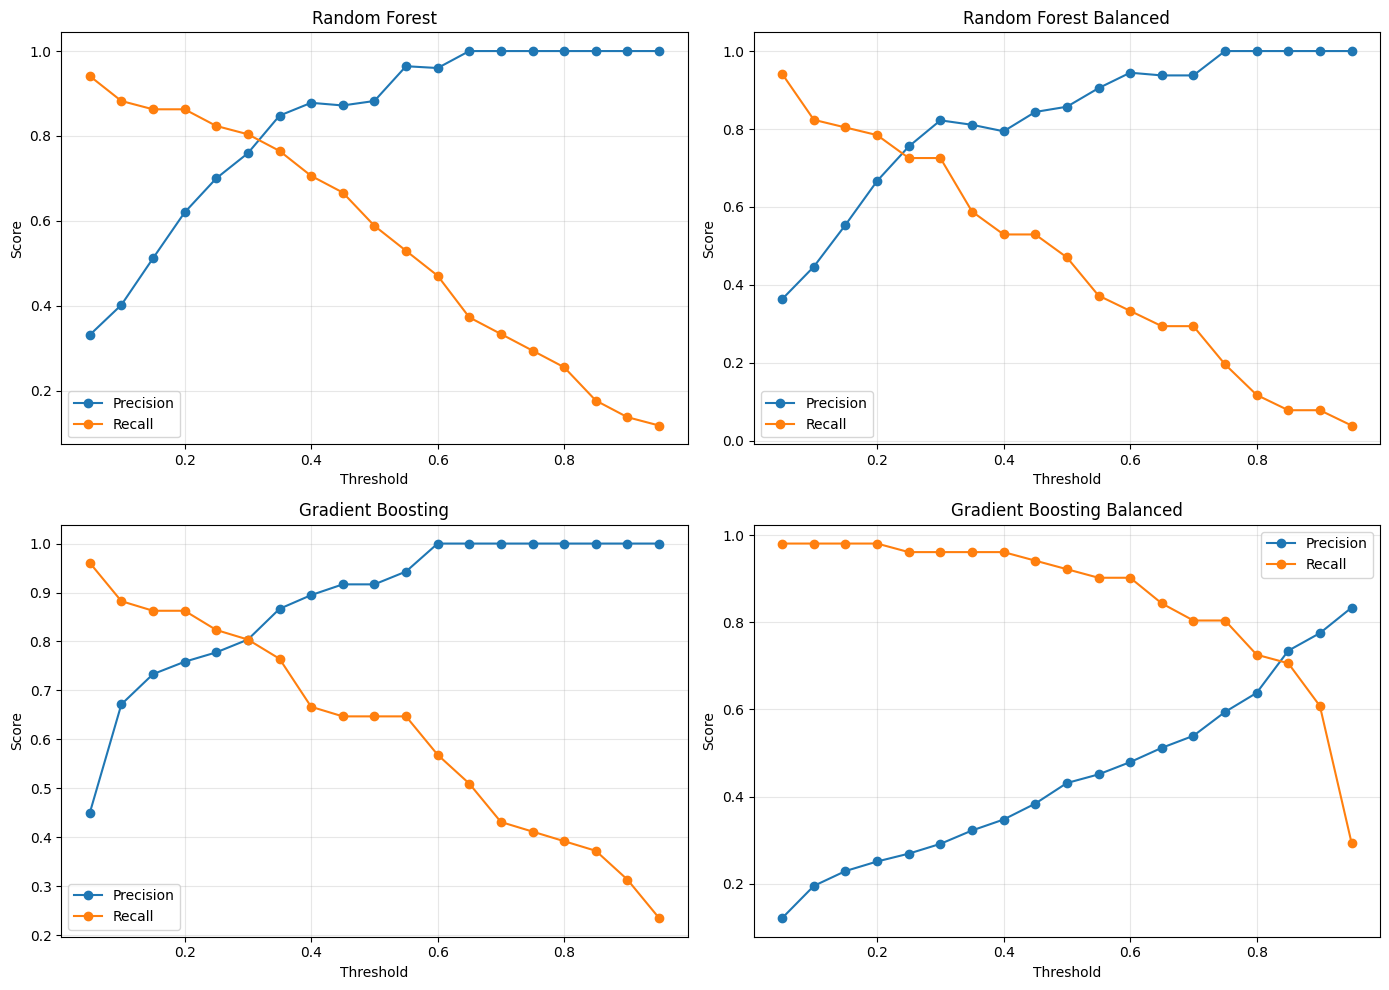

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, model_name in zip(
    axes.flatten(),
    threshold_results_tree["Model"].unique()
):

    subset = threshold_results_tree[
        threshold_results_tree["Model"] == model_name
    ]

    ax.plot(
        subset["Threshold"],
        subset["Precision"],
        marker="o",
        label="Precision"
    )

    ax.plot(
        subset["Threshold"],
        subset["Recall"],
        marker="o",
        label="Recall"
    )

    ax.set_title(model_name)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Score")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
threshold_summary = []

for model_name, group in threshold_results_tree.groupby("Model"):

    # Best F1-score
    best_f1 = group.loc[group["F1-score"].idxmax()]

    # Highest precision while maintaining recall >= 0.80
    high_recall = group[group["Recall"] >= 0.80]

    if not high_recall.empty:
        best_high_recall = high_recall.loc[
            high_recall["Precision"].idxmax()
        ]
    else:
        best_high_recall = None

    # Highest precision while maintaining recall >= 0.60
    moderate_recall = group[group["Recall"] >= 0.60]

    if not moderate_recall.empty:
        best_moderate_recall = moderate_recall.loc[
            moderate_recall["Precision"].idxmax()
        ]
    else:
        best_moderate_recall = None

    threshold_summary.append({
        "Model": model_name,

        "Best F1 Threshold": best_f1["Threshold"],
        "Best F1": best_f1["F1-score"],

        "Best Precision (Recall >= 0.80)":
            best_high_recall["Precision"]
            if best_high_recall is not None else np.nan,

        "Threshold at Recall >= 0.80":
            best_high_recall["Threshold"]
            if best_high_recall is not None else np.nan,

        "Best Precision (Recall >= 0.60)":
            best_moderate_recall["Precision"]
            if best_moderate_recall is not None else np.nan,

        "Threshold at Recall >= 0.60":
            best_moderate_recall["Threshold"]
            if best_moderate_recall is not None else np.nan
    })

threshold_summary_df = pd.DataFrame(threshold_summary)

display(threshold_summary_df.round(4))

,Model,Best F1 Threshold,Best F1,Best Precision (Recall >= 0.80),Threshold at Recall >= 0.80,Best Precision (Recall >= 0.60),Threshold at Recall >= 0.60
0,Gradient Boosting,0.35,0.8125,0.8039,0.30,0.9429,0.55
1,Gradient Boosting Balanced,0.85,0.7200,0.5942,0.75,0.7750,0.90
2,Random Forest,0.35,0.8041,0.7593,0.30,0.8780,0.40
3,Random Forest Balanced,0.30,0.7708,0.5541,0.15,0.8222,0.30


In [43]:
gb_operating_points = threshold_results_tree[
    (threshold_results_tree["Model"] == "Gradient Boosting") &
    (threshold_results_tree["Threshold"].isin([0.30, 0.35, 0.55]))
].copy()

display(
    gb_operating_points[
        [
            "Threshold",
            "Precision",
            "Recall",
            "F1-score",
            "TP",
            "FP",
            "FN",
            "TN"
        ]
    ].round(4)
)

,Threshold,Precision,Recall,F1-score,TP,FP,FN,TN
43,0.30,0.8039,0.8039,0.8039,41,10,10,1439
44,0.35,0.8667,0.7647,0.8125,39,6,12,1443
48,0.55,0.9429,0.6471,0.7674,33,2,18,1447


### Interpretation: Operating Points, Not a Single Best Threshold

**Observed.** Best operating points per model (validation set):

| Model | Best F1 | At threshold | Best precision with recall ≥ 0.80 | Best precision with recall ≥ 0.60 |
|---|---:|---:|---:|---:|
| Gradient Boosting | 0.8125 | 0.35 | 0.8039 (threshold 0.30) | 0.9429 (threshold 0.55) |
| Random Forest | 0.8041 | 0.35 | 0.7593 (threshold 0.30) | 0.8780 (threshold 0.40) |
| Random Forest Balanced | 0.7708 | 0.30 | 0.5541 (threshold 0.15) | 0.8222 (threshold 0.30) |
| Gradient Boosting Balanced | 0.7200 | 0.85 | 0.5942 (threshold 0.75) | 0.7750 (threshold 0.90) |

Three operating points for the original Gradient Boosting model:

| Threshold | Precision | Recall | F1 | TP | FP | FN | TN |
|---:|---:|---:|---:|---:|---:|---:|---:|
| 0.30 | 0.8039 | 0.8039 | 0.8039 | 41 | 10 | 10 | 1439 |
| 0.35 | 0.8667 | 0.7647 | 0.8125 | 39 | 6 | 12 | 1443 |
| 0.55 | 0.9429 | 0.6471 | 0.7674 | 33 | 2 | 18 | 1447 |

**What this means.** The ranking of models seen at threshold 0.5 holds up across thresholds: standard Gradient Boosting remains the best performer, and the balanced variants do not reach its best F1 at any threshold (0.7200 and 0.7708 versus 0.8125). Weighting mostly shifts the operating points; it does not create better ones.

Within the Gradient Boosting model, these three thresholds are different trade-offs and not better or worse versions of the same result. At 0.30, 41 of 51 failures are detected with 10 false alarms. Raising the threshold to 0.55 cuts false alarms to 2 but misses 18 failures rather than 10. At 0.35 the model sits in between and attains the highest F1 in the scan. Which of these is preferable depends on how costly a missed failure is compared with a false alert, a question this notebook does not attempt to answer with an invented cost model.

**Decision.** Gradient Boosting is selected as the main candidate for hyperparameter optimisation, because it leads in PR-AUC, ROC-AUC and best F1, and because its operating points span a useful range of precision and recall.

**Next.** Tune Gradient Boosting using cross-validation on the training set only.

## 3.7 Hyperparameter Optimisation of Gradient Boosting

**Objective.** Determine whether better hyperparameters than the scikit-learn defaults used so far improve the Gradient Boosting model.

**Rationale.** The default hyperparameters are a reasonable generic starting point, not an optimum for this dataset. Gradient Boosting has several interacting hyperparameters (number of trees, learning rate, tree depth, leaf size, subsampling, feature subsampling), and searching them systematically is more reliable than adjusting them by hand.

**Method.**

* **`RandomizedSearchCV`** samples 40 candidate configurations at random from specified distributions rather than enumerating a full grid. With several continuous and integer hyperparameters, a grid would be very expensive, and random sampling explores each hyperparameter's range more efficiently for the same budget.
* **`StratifiedKFold` with 5 folds** (shuffled, `random_state=42`) keeps the failure proportion similar in every fold. With only 237 training failures, a non-stratified split could leave a fold with very few failures, making its score unreliable.
* **Scoring by `average_precision`** (PR-AUC), the same primary metric used throughout, because it focuses on the rare class and does not depend on a single threshold.
* **`refit=True`**, so the best configuration is retrained on the full training set.
* **Training data only.** The search uses `X_train_selected` and `y_train`. The validation set is reserved for evaluating the outcome, and the test set must not influence hyperparameter choices at all; otherwise the final evaluation would no longer be an unbiased estimate.

The search space is defined in the next cell: `n_estimators` 50–300, `learning_rate` 0.01–0.20, `max_depth` 2–5, `min_samples_split` 2–20, `min_samples_leaf` 1–10, `subsample` 0.7–1.0, and `max_features` among `None`, `"sqrt"` and `"log2"`. With 5 folds and 40 candidates, the search performs 200 model fits.

In [44]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

gb_search_pipeline = Pipeline([
    ("preprocessor", tree_preprocessor),
    ("classifier", GradientBoostingClassifier(
        random_state=42
    ))
])

In [45]:
from scipy.stats import randint, uniform

param_distributions = {
    "classifier__n_estimators": randint(50, 301),
    "classifier__learning_rate": uniform(0.01, 0.19),
    "classifier__max_depth": randint(2, 6),
    "classifier__min_samples_split": randint(2, 21),
    "classifier__min_samples_leaf": randint(1, 11),
    "classifier__subsample": uniform(0.7, 0.3),
    "classifier__max_features": [None, "sqrt", "log2"]
}

In [46]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=gb_search_pipeline,
    param_distributions=param_distributions,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

random_search.fit(X_train_selected, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('cat',
                                                                               OneHotEncoder(handle_unknown='ignore',
                                                                                             sparse_output=False),
                                                                               ['Type'])])),
                                             ('classifier',
                                              GradientBoostingClassifier(random_state=42))]),
                   n_iter=40, n_jobs=-1,
                   param_distrib...
                                        'classifier__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e039c2bc690>,
                                        'classifier__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x7e039c9aba10>,
                                        'classifier__subsample': <scipy.stats._distn_infrastructure.rv_continuous_frozen object at 0x7e039c2bc7d0>},
                   random_state=42, scoring='average_precision', verbose=1)

In [47]:
print("Best CV PR-AUC:", random_search.best_score_)

print("\nBest Parameters:")
for parameter, value in random_search.best_params_.items():
    print(f"{parameter}: {value}")

Best CV PR-AUC: 0.8357980017538985

Best Parameters:
classifier__learning_rate: 0.05347165144340827
classifier__max_depth: 5
classifier__max_features: log2
classifier__min_samples_leaf: 3
classifier__min_samples_split: 3
classifier__n_estimators: 219
classifier__subsample: 0.942436113869325


### Interpretation: Search Result

**Observed.** The best cross-validated PR-AUC is **0.8358**, obtained with:

| Hyperparameter | Value |
|---|---|
| `n_estimators` | 219 |
| `learning_rate` | 0.0535 |
| `max_depth` | 5 |
| `max_features` | `"log2"` |
| `min_samples_leaf` | 3 |
| `min_samples_split` | 3 |
| `subsample` | 0.9424 |

**What this means.** The selected configuration uses a lower learning rate than the default (0.1) with more trees, and deeper trees (depth 5 instead of 3). It also includes several randomisation elements typical of stochastic gradient boosting: random feature subsampling at each split (`max_features="log2"`) and a subsample fraction below 1.0.

**Limitations.**

* The 0.8358 figure is a cross-validated estimate on the *training* data and must not be compared directly with the validation PR-AUC of 0.8961 that the untuned model obtained earlier; the data subsets differ, and the untuned model was not scored by the same cross-validation, so this number alone does not show whether tuning helped.
* The best `max_depth` (5) is at the upper edge of the range that was searched, so a deeper range was not explored.

**Next.** The tuned model is compared with the original on the validation set.

## 3.8 Tuned Model Evaluation

**Objective.** Check how the tuned model performs on the validation set, and compare it with the original Gradient Boosting model.

**Rationale.** The search optimised cross-validated PR-AUC on training folds. Whether that translates into better validation behaviour is an empirical question and should not be assumed.

**Method.** Retrieve `best_estimator_` as `tuned_gb`, score the validation set, report PR-AUC, ROC-AUC, the confusion matrix and the classification report at threshold 0.5, and then compare it with the original Gradient Boosting model on the same metrics.

In [48]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

tuned_gb = random_search.best_estimator_

# Predict probabilities
y_val_proba_tuned = tuned_gb.predict_proba(X_val_selected)[:, 1]

# Default threshold = 0.5
y_val_pred_tuned = (y_val_proba_tuned >= 0.5).astype(int)

print("Tuned Gradient Boosting — Validation Results")
print("-" * 50)

print(f"PR-AUC:  {average_precision_score(y_val, y_val_proba_tuned):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_val, y_val_proba_tuned):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_tuned))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_tuned))

Tuned Gradient Boosting — Validation Results
--------------------------------------------------
PR-AUC:  0.8672
ROC-AUC: 0.9820

Confusion Matrix:
[[1446    3]
 [  17   34]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1449
           1       0.92      0.67      0.77        51

    accuracy                           0.99      1500
   macro avg       0.95      0.83      0.88      1500
weighted avg       0.99      0.99      0.99      1500



In [49]:
from sklearn.metrics import precision_score, recall_score, f1_score

models_to_compare = {
    "Original Gradient Boosting": gb_model,
    "Tuned Gradient Boosting": tuned_gb
}

comparison_results = []

for model_name, model in models_to_compare.items():

    if model_name == "Original Gradient Boosting":
        X_eval = X_val_selected
    else:
        X_eval = X_val_selected

    y_proba = model.predict_proba(X_eval)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    comparison_results.append({
        "Model": model_name,
        "PR-AUC": average_precision_score(y_val, y_proba),
        "ROC-AUC": roc_auc_score(y_val, y_proba),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_results)
comparison_df.round(4)

,Model,PR-AUC,ROC-AUC,Precision,Recall,F1
0,Original Gradient Boosting,0.8961,0.980,0.9167,0.6471,0.7586
1,Tuned Gradient Boosting,0.8672,0.982,0.9189,0.6667,0.7727


### Interpretation: Tuning Did Not Improve Every Metric

**Observed.** Validation results at threshold 0.5:

| Metric | Original Gradient Boosting | Tuned Gradient Boosting |
|---|---:|---:|
| PR-AUC | **0.8961** | 0.8672 |
| ROC-AUC | 0.9800 | **0.9820** |
| Precision | 0.9167 | **0.9189** |
| Recall | 0.6471 | **0.6667** |
| F1 | 0.7586 | **0.7727** |

The tuned model's confusion matrix at 0.5 is `[[1446, 3], [17, 34]]`, against 33 true positives and 3 false positives for the original.

**What this means.** The outcome is mixed. The tuned model is slightly better on ROC-AUC, precision, recall and F1 at threshold 0.5, but **the original model has the higher validation PR-AUC (0.8961 against 0.8672)**. Since PR-AUC was the metric used to guide tuning and to compare models, this is not a result to hide. The threshold-0.5 differences correspond to a single additional detected failure (34 versus 33), so they are small relative to the noise expected from 51 validation failures. The same noise limits how firmly the PR-AUC difference can be interpreted in either direction.

**Decision.** The comparison cannot be settled by one number at one threshold. Both models are carried into the operating-point analysis, where precision, recall and the actual alert counts can be compared directly.

## 3.9 Operating Threshold Selection

**Objective.** Choose the decision threshold for the final system and decide between the original and tuned models.

**Rationale.** PR-AUC summarises performance over all thresholds, but a deployed system has to commit to one. Selecting the threshold is part of the model-selection process and, to keep the test set unbiased, it has to be done on validation data.

**Method.** Evaluate the tuned model at thresholds from 0.05 to 0.95 in steps of 0.05. Then apply three selection rules: the best F1, the highest precision with recall at least 0.80, and the highest precision with recall at least 0.60.

In [50]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.05, 1.00, 0.05):

    y_pred = (y_val_proba_tuned >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0),
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

tuned_threshold_df = pd.DataFrame(threshold_results)

tuned_threshold_df.round(4)

,Threshold,Precision,Recall,F1,TP,FP,FN,TN
0,0.05,0.5542,0.9020,0.6866,46,37,5,1412
1,0.10,0.6984,0.8627,0.7719,44,19,7,1430
2,0.15,0.7500,0.8235,0.7850,42,14,9,1435
3,0.20,0.8367,0.8039,0.8200,41,8,10,1441
4,0.25,0.8605,0.7255,0.7872,37,6,14,1443
5,0.30,0.9000,0.7059,0.7912,36,4,15,1445
6,0.35,0.9000,0.7059,0.7912,36,4,15,1445
7,0.40,0.9231,0.7059,0.8000,36,3,15,1446
8,0.45,0.9211,0.6863,0.7865,35,3,16,1446
9,0.50,0.9189,0.6667,0.7727,34,3,17,1446


In [51]:
# Best F1
best_f1_row = tuned_threshold_df.loc[
    tuned_threshold_df["F1"].idxmax()
]

# Highest precision while maintaining recall >= 0.80
high_recall_candidates = tuned_threshold_df[
    tuned_threshold_df["Recall"] >= 0.80
]

best_precision_high_recall = (
    high_recall_candidates.loc[
        high_recall_candidates["Precision"].idxmax()
    ]
    if not high_recall_candidates.empty else None
)

# Highest precision while maintaining recall >= 0.60
moderate_recall_candidates = tuned_threshold_df[
    tuned_threshold_df["Recall"] >= 0.60
]

best_precision_moderate_recall = (
    moderate_recall_candidates.loc[
        moderate_recall_candidates["Precision"].idxmax()
    ]
    if not moderate_recall_candidates.empty else None
)

print("Best F1 Operating Point:")
display(best_f1_row.to_frame().T)

print("\nBest Precision with Recall >= 0.80:")
display(
    best_precision_high_recall.to_frame().T
    if best_precision_high_recall is not None else "No qualifying threshold"
)

print("\nBest Precision with Recall >= 0.60:")
display(
    best_precision_moderate_recall.to_frame().T
    if best_precision_moderate_recall is not None else "No qualifying threshold"
)

Best F1 Operating Point:


,Threshold,Precision,Recall,F1,TP,FP,FN,TN
3,0.2,0.836735,0.803922,0.82,41.0,8.0,10.0,1441.0



Best Precision with Recall >= 0.80:


,Threshold,Precision,Recall,F1,TP,FP,FN,TN
3,0.2,0.836735,0.803922,0.82,41.0,8.0,10.0,1441.0



Best Precision with Recall >= 0.60:


,Threshold,Precision,Recall,F1,TP,FP,FN,TN
13,0.7,0.941176,0.627451,0.752941,32.0,2.0,19.0,1447.0


### Interpretation and Final Model-Selection Decision

**Observed.** The two contrasting operating points for the tuned model:

| Threshold | Precision | Recall | F1 | TP | FP | FN | TN |
|---:|---:|---:|---:|---:|---:|---:|---:|
| **0.20** | 0.8367 | 0.8039 | **0.8200** | 41 | 8 | 10 | 1441 |
| 0.70 | 0.9412 | 0.6275 | 0.7529 | 32 | 2 | 19 | 1447 |

* Threshold **0.20** gives the best F1 in the scan. It is also the highest-precision threshold among those with recall at or above 0.80.
* Threshold **0.70** is the highest-precision threshold with recall at or above 0.60.

**What the difference means.** Moving from 0.20 to 0.70 removes 6 false alarms (8 to 2) but misses 9 more failures (10 to 19). A threshold of 0.20 favours detection; a threshold of 0.70 favours alert reliability. Neither is "correct" in general. Which one is better depends on the relative cost of a missed failure and an unnecessary inspection, and that cost has not been defined for this project.

**Decision.** The selected final configuration is **Tuned Gradient Boosting with a decision threshold of 0.20.**

**Rationale for the choice.**

* At 0.20 the tuned model catches 41 of 51 validation failures (recall 0.8039) with 8 false positives, and it reaches the highest F1 of the scan (0.8200). Compared with its own default threshold of 0.5 (F1 0.7727, recall 0.6667), this is a clear gain in recall at a modest cost in precision (0.9189 to 0.8367).
* Compared with the original Gradient Boosting model, the best F1 is 0.8200 for the tuned model versus 0.8125 for the original (at 0.35), and at an identical recall of 0.8039 the tuned model produces 8 false positives against 10 for the original (at threshold 0.30).

**Transparency about the choice.**

* The original Gradient Boosting model had the **higher validation PR-AUC** (0.8961 versus 0.8672). Selecting the tuned model is a judgement about operating-point behaviour, not a claim that it is superior on every metric.
* The differences that favour the tuned model are small, a matter of one or two cases out of 51 failures.
* The threshold was selected by maximising F1 over the tested values, and the F1 curve is not smooth (F1 is 0.7850 at 0.15, 0.8200 at 0.20 and 0.7872 at 0.25), so 0.20 is an empirical choice that carries uncertainty and is not a universal optimum.
* Because both the model and the threshold were chosen using validation data, validation metrics at the selected operating point are somewhat optimistic. This is the reason the untouched test set is needed.
* No formal industrial cost matrix was defined. F1 gives equal importance to precision and recall, and that is an assumption, not a measured business requirement.

**Next.** Before the final evaluation, permutation importance is used to inspect what the selected model relies on.

## 3.10 Permutation Feature Importance

**Objective.** Understand which input features the selected model depends on.

**Rationale.** A model that performs well should still be inspectable. Knowing which features it relies on helps detect implausible behaviour and gives a basis for discussing the model with domain experts.

**Method.** *Permutation importance* randomly shuffles the values of one feature at a time, breaking its relationship with the target, and measures how much model performance falls. A large drop means the model relied on that feature. Here the performance measure is `average_precision` (PR-AUC), consistent with the primary metric of this project, and the drop is averaged over `n_repeats=20` shuffles (`random_state=42`). It is computed on the **validation set**, so that it reflects reliance on patterns that carry over to unseen data, not memorisation of the training set.

$$\text{Importance}_j = \text{PR-AUC}_{\text{original}} - \overline{\text{PR-AUC}}_{\text{feature } j \text{ shuffled}}$$

In [52]:
from sklearn.inspection import permutation_importance

# Calculate permutation importance on the validation set
permutation_result = permutation_importance(
    tuned_gb,
    X_val_selected,
    y_val,
    scoring="average_precision",
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

# Create a results DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": X_val_selected.columns,
    "Importance Mean": permutation_result.importances_mean,
    "Importance Std": permutation_result.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance Mean",
    ascending=False
)

feature_importance_df.round(5)

,Feature,Importance Mean,Importance Std
0,Air temperature,0.49548,0.03023
2,Rotational speed,0.36144,0.03386
4,Tool wear,0.33748,0.02889
5,Power,0.29898,0.03752
1,Process temperature,0.24167,0.02680
3,Torque,0.08292,0.02691
6,Type,0.01596,0.00877


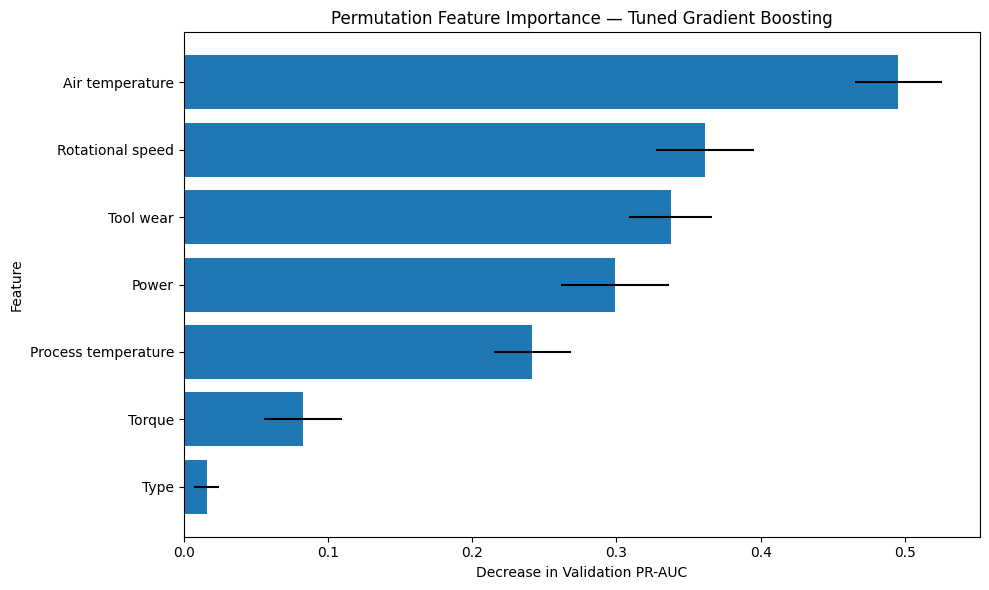

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance_df["Feature"],
    feature_importance_df["Importance Mean"],
    xerr=feature_importance_df["Importance Std"]
)

plt.xlabel("Decrease in Validation PR-AUC")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance — Tuned Gradient Boosting")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### Interpretation: What the Model Relies On

**Observed.**

| Feature | Importance (mean decrease in PR-AUC) | Std over 20 shuffles |
|---|---:|---:|
| Air temperature | 0.49548 | 0.03023 |
| Rotational speed | 0.36144 | 0.03386 |
| Tool wear | 0.33748 | 0.02889 |
| Power | 0.29898 | 0.03752 |
| Process temperature | 0.24167 | 0.02680 |
| Torque | 0.08292 | 0.02691 |
| Type | 0.01596 | 0.00877 |

**What this means.** Shuffling air temperature degrades the model's validation PR-AUC the most, followed by rotational speed, tool wear, power and process temperature. Torque and `Type` matter far less. The ranking should be read carefully:

* **Importance is not causation.** It describes what this fitted model uses to make predictions, not which variables cause failures.
* **It is not the same as the box-plot picture.** Air temperature showed only a modest shift between classes in Section 1.7, but it ranks first here. Permutation importance measures a feature's contribution *given* the others, including through interactions. One possible reading, consistent with the data but not tested here, is that the temperature features matter partly in combination (for example through the relation between air and process temperature), which would also fit the observation that process temperature ranks fifth.
* **Correlated or derived features share importance.** `Power` is computed from `Torque` and `Rotational speed`, so these three carry overlapping information. The low score for `Torque` does not mean torque is physically unimportant; its information may be partly available to the model through `Power` and `Rotational speed`.
* **A low score does not justify automatic removal.** `Type` has the lowest importance (0.01596) and a standard deviation (0.00877) that is more than half its mean, so its contribution is small and not precisely measured. That is consistent with the weak association found in Section 1.5, but a small importance on one validation set is not by itself grounds for deleting a feature.
* The standard deviation reflects variation across random shuffles of this one validation set. It is not a confidence interval for how the importance would vary on new data.

**Next.** The final model is evaluated on the test set.

# Phase 4 — Final Test Evaluation

**Objective.** Obtain an unbiased estimate of the selected configuration's performance.

**Rationale.** Every earlier decision (features, model family, hyperparameters, threshold) used the training or validation data. The test set has played no role in them, so it is the only data that can give an honest estimate of how the final decision rule behaves on records it has never influenced.

**Method.** Apply the tuned model, with the threshold of 0.20 fixed in advance on the basis of validation data, to the test set. The threshold is not adjusted after seeing test results. The first cell below selects the test features and the second computes the metrics once.

In [54]:
X_test_selected = X_test[selected_features]

In [55]:
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

FINAL_THRESHOLD = 0.20

# Predict failure scores on the untouched test set
y_test_proba = tuned_gb.predict_proba(X_test_selected)[:, 1]

# Apply the threshold selected using validation data
y_test_pred = (y_test_proba >= FINAL_THRESHOLD).astype(int)

print("MachineGuard — Final Test Evaluation")
print("=" * 50)

print(f"PR-AUC:   {average_precision_score(y_test, y_test_proba):.4f}")
print(f"ROC-AUC:  {roc_auc_score(y_test, y_test_proba):.4f}")
print(f"Accuracy: {accuracy_score(y_test, y_test_pred):.4f}")
print(f"Precision:{precision_score(y_test, y_test_pred):.4f}")
print(f"Recall:   {recall_score(y_test, y_test_pred):.4f}")
print(f"F1-score: {f1_score(y_test, y_test_pred):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

MachineGuard — Final Test Evaluation
PR-AUC:   0.8559
ROC-AUC:  0.9788
Accuracy: 0.9847
Precision:0.7692
Recall:   0.7843
F1-score: 0.7767

Confusion Matrix:
[[1437   12]
 [  11   40]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1449
           1       0.77      0.78      0.78        51

    accuracy                           0.98      1500
   macro avg       0.88      0.89      0.88      1500
weighted avg       0.98      0.98      0.98      1500



### Interpretation: Test Results

**Observed.** Test performance of Tuned Gradient Boosting at threshold 0.20:

| Metric | Test result |
|---|---:|
| PR-AUC | 0.8559 |
| ROC-AUC | 0.9788 |
| Accuracy | 0.9847 |
| Precision | 0.7692 |
| Recall | 0.7843 |
| F1-score | 0.7767 |

Confusion matrix: `[[1437, 12], [11, 40]]`.

* **40** failures were correctly detected (true positives).
* **11** failures were missed (false negatives).
* **12** false alerts were raised on normal records (false positives).
* **1,437** normal records were correctly classified (true negatives).

**Validation versus test.**

| Metric | Validation | Test |
|---|---:|---:|
| PR-AUC | 0.8672 | 0.8559 |
| ROC-AUC | 0.9820 | 0.9788 |
| Precision (threshold 0.20) | 0.8367 | 0.7692 |
| Recall (threshold 0.20) | 0.8039 | 0.7843 |
| F1 (threshold 0.20) | 0.8200 | 0.7767 |

**What this means.** The final model detects roughly four out of five failures (40 of 51) with 12 false alerts among 1,449 normal records. Accuracy is 0.9847, but as Section 3.1 showed, accuracy alone is not informative here; the precision, recall and PR-AUC values carry the evidence. Every metric is modestly lower on the test set than on validation. In counts, this is a change from 41 to 40 true positives and from 8 to 12 false positives.

A modest decline is expected. The model and the threshold were selected on validation data, and picking the maximum of a noisy curve tends to produce slightly optimistic validation numbers. The decline is also small in absolute terms, which is consistent with the model not being badly tailored to the validation set. It does not, however, prove that overfitting is absent: with this sample size, the test result cannot separate genuine over-optimism from ordinary sampling variation.

**Limitations.**

* **Few positive examples.** The test set has only 51 failures. One failure changes recall by about 2 percentage points, and precision rests on only 52 alerts. Minority-class metrics therefore carry substantial uncertainty, and the notebook does not compute confidence intervals.
* **Single split.** The results come from one random partition (`random_state=42`).
* **Synthetic data.** The results describe performance on the AI4I 2020 dataset and do not demonstrate generalisation to real factories, to other machines or to data with different failure patterns.
* **No cost model.** The threshold reflects F1 maximisation, not a defined operational cost.

# Model Persistence and Inference Verification

**Objective.** Save everything needed to reproduce a prediction, and confirm that the saved model can be reloaded and used.

**Rationale.** A trained model is not directly usable by a service unless its surrounding information travels with it. Saving only the estimator would leave the decision threshold, the expected inputs and the model identity to be reconstructed elsewhere, which is a common source of mistakes.

**Method.** Package a single artifact with `joblib` and store it as `artifacts/machineguard_model.joblib`. It contains:

| Key | Content | Why it matters |
|---|---|---|
| `model` | The tuned pipeline (preprocessing and Gradient Boosting) | Raw inputs can be scored without re-implementing preprocessing |
| `threshold` | 0.20 | The decision rule is part of the model's behaviour |
| `features` | The seven selected input columns | Defines the input schema a future service must supply |
| `model_name` | "Tuned Gradient Boosting" | Identifies what is deployed |
| `version` | "1.0.0" | Allows traceability and future version management |

In [56]:
import joblib
from pathlib import Path

# Create artifacts directory
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)

FINAL_THRESHOLD = 0.20

# Package everything needed for inference
machineguard_artifact = {
    "model": tuned_gb,
    "threshold": FINAL_THRESHOLD,
    "features": selected_features,
    "model_name": "Tuned Gradient Boosting",
    "version": "1.0.0"
}

# Save artifact
model_path = ARTIFACTS_DIR / "machineguard_model.joblib"

joblib.dump(machineguard_artifact, model_path)

print(f"Model saved successfully: {model_path}")

Model saved successfully: artifacts/machineguard_model.joblib


### Reload and smoke test

The artifact is loaded again from disk and one test record (`X_test_selected.iloc[[0]]`) is scored, applying the stored threshold to produce a class.

In [57]:
loaded_artifact = joblib.load(model_path)

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]
loaded_features = loaded_artifact["features"]

# Test inference using one test sample
sample = X_test_selected.iloc[[0]]

sample_score = loaded_model.predict_proba(sample)[:, 1][0]
sample_prediction = int(sample_score >= loaded_threshold)

print("Loaded model:", loaded_artifact["model_name"])
print("Model version:", loaded_artifact["version"])
print("Failure score:", round(sample_score, 4))
print("Predicted class:", sample_prediction)

Loaded model: Tuned Gradient Boosting
Model version: 1.0.0
Failure score: 0.0003
Predicted class: 0


### Interpretation: What the Smoke Test Does and Does Not Show

**Observed.** The reloaded artifact reports the model "Tuned Gradient Boosting", version "1.0.0", a failure score of 0.0003 for the sample, and a predicted class of 0.

**What this means.** The artifact can be saved, loaded and used to produce a risk score and a class label from the stored threshold. The score of 0.0003 is far below the threshold of 0.20, so the record is classified as normal.

**Limitations.** This is a **smoke test** on a single record in the same environment. It verifies that the saved model loads and predicts. It is not an API integration test, a test of input validation, a comparison of reloaded and original predictions across many records, or a deployment test. Pickle-based artifacts such as this one are also sensitive to the library versions used to create them, which a serving environment will have to take into account.

# Conclusions, Limitations and Next Steps

## What the experiments established

1. **The problem is a rare-event classification task.** Only 3.39% of records are failures, so accuracy is misleading: a model that never predicts failure reaches 0.9660 accuracy with zero recall. PR-AUC, precision, recall and F1 were used instead.
2. **Machine type has a statistically significant but practically small association with failure** (Chi-Square $p = 0.001032$; failure rates from 2.09% to 3.92%). Outliers in rotational speed and torque were retained as legitimate operating observations.
3. **Mechanical power was the more useful engineered feature.** In a controlled Logistic Regression ablation, adding `Power` gave the best PR-AUC and a clear ROC-AUC gain, whereas `Temp_Diff` added no meaningful improvement. The final feature set is the original features plus `Power`.
4. **Non-linear models were decisively better than linear ones.** Logistic Regression plateaued at PR-AUC of about 0.39; Gradient Boosting reached 0.8961 on the validation set. Class weighting shifted operating points but did not improve the strongest models.
5. **Tuning gave a mixed validation result.** Cross-validated hyperparameter search produced a model with slightly better threshold-0.5 metrics and ROC-AUC, but lower validation PR-AUC than the untuned model (0.8672 versus 0.8961).
6. **The selected configuration is Tuned Gradient Boosting at a threshold of 0.20**, chosen from validation operating points because it gave the best F1 (0.8200) and recall of 0.8039 with 8 false positives.
7. **On the untouched test set** the selected configuration achieved PR-AUC 0.8559, ROC-AUC 0.9788, precision 0.7692, recall 0.7843 and F1 0.7767 (40 of 51 failures detected, 12 false alerts).

## Final configuration

| Item | Value |
|---|---|
| Model | Gradient Boosting (tuned), inside a pipeline with one-hot encoding of `Type` |
| Features | `Air temperature`, `Process temperature`, `Rotational speed`, `Torque`, `Tool wear`, `Power`, `Type` |
| Decision threshold | 0.20 |
| Key hyperparameters | 219 trees, learning rate 0.0535, max depth 5, `max_features="log2"`, `subsample` 0.9424 |
| Artifact | `artifacts/machineguard_model.joblib`, version 1.0.0 |

## Limitations

* **Synthetic data.** All conclusions apply to the AI4I 2020 dataset. They are not evidence of real-world industrial performance.
* **Small number of failures.** Validation and test sets each contain 51 failures, so differences of a few cases between models or thresholds are within plausible noise. No confidence intervals or repeated resampling were used.
* **Single data split.** Model and threshold selection relied on one validation set, and the final evaluation on one test set.
* **Original model had higher validation PR-AUC.** The choice of the tuned model rests on operating-point behaviour and not on PR-AUC.
* **Empirical threshold.** The 0.20 threshold maximises validation F1 and does not reflect a real cost structure. A deployment would need to set the threshold according to the true costs of missed failures and false alarms.
* **Feature interpretation.** Permutation importance describes model reliance, not causes of failure. `Temp_Diff` was evaluated only with a linear model.
* **Task definition.** The system estimates failure risk from current operating conditions. It does not estimate remaining useful life or forecast failures in advance.

## Next engineering steps (planned, not yet implemented)

1. **FastAPI inference service** that loads the saved artifact and exposes a prediction endpoint, with Pydantic validation of the seven input features.
2. **Automated tests** with pytest covering input validation, prediction behaviour and artifact loading.
3. **Docker packaging** of the service for a reproducible runtime.
4. **Cloud deployment and documentation.**

The cells that follow are empty trailing cells retained from the original notebook.